In [809]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [810]:
# Load datasets from DATA folder

customers = pd.read_csv("DATA/customers.csv")
usage = pd.read_csv("DATA/usage_behavior.csv")
transactions = pd.read_csv("DATA/service_transactions.csv")

print("Customers:", customers.shape)
print("Usage:", usage.shape)
print("Transactions:", transactions.shape)


Customers: (3015, 18)
Usage: (2000, 13)
Transactions: (12993, 2)


In [811]:

customers.head()


,customer_id,age,gender,governorate,tenure_months,contract_type,plan,payment_method,device_type,has_home_internet,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp,churn
0,C02198,36.0,Female,Gharbia,6,2-Year,Standard,Cash at store,Android,No,35.2,468.0,37,4,0,0,453.62,No
1,C00641,18.0,Female,Minya,69,Monthly,Standard,Bank transfer,iPhone,Yes,40.7,230.0,23,2,3,0,430.42,No
2,C02273,44.0,Female,Giza,3,1-Year,Basic,Cash at store,Android,No,NaN,398.0,36,3,1,3,239.72,Yes
3,C02864,73.0,Male,Beni Suef,3,Monthly,Premium,Cash at store,iPhone,Yes,25.7,377.0,46,5,0,3,616.94,Yes
4,C01307,24.0,Male,Aswan,10,Monthly,Premium,Cash at store,Android,Yes,71.6,206.0,18,3,0,0,737.98,No


In [812]:

# Check data types for all datasets

print("CUSTOMERS DATA TYPES")
print(customers.dtypes)

print("\nUSAGE BEHAVIOR DATA TYPES")
print(usage.dtypes)

print("\nSERVICE TRANSACTIONS DATA TYPES")
print(transactions.dtypes)


CUSTOMERS DATA TYPES
customer_id              str
age                  float64
gender                   str
governorate              str
tenure_months          int64
contract_type            str
plan                     str
payment_method           str
device_type              str
has_home_internet        str
data_usage_gb        float64
voice_minutes        float64
sms_count              int64
num_services           int64
support_calls          int64
late_payments          int64
monthly_bill_egp     float64
churn                    str
dtype: object

USAGE BEHAVIOR DATA TYPES
customer_id                    str
avg_daily_data_mb          float64
night_usage_pct            float64
streaming_hours_week       float64
social_media_hours_week    float64
gaming_hours_week          float64
calls_per_day              float64
avg_call_minutes           float64
intl_calls_month             int64
roaming_days_year            int64
topups_per_month             int64
app_count                    in

In [813]:

for name, df in {
    "Customers": customers,
    "Usage Behavior": usage,
    "Service Transactions": transactions
}.items():
    print(f"\n{name} Missing Values:")
    print(df.isnull().sum())



Customers Missing Values:
customer_id           0
age                  90
gender                0
governorate           0
tenure_months         0
contract_type         0
plan                  0
payment_method       60
device_type           0
has_home_internet     0
data_usage_gb        90
voice_minutes        60
sms_count             0
num_services          0
support_calls         0
late_payments         0
monthly_bill_egp      0
churn                 0
dtype: int64

Usage Behavior Missing Values:
customer_id                 0
avg_daily_data_mb           0
night_usage_pct             0
streaming_hours_week        0
social_media_hours_week    25
gaming_hours_week           0
calls_per_day               0
avg_call_minutes            0
intl_calls_month            0
roaming_days_year           0
topups_per_month            0
app_count                   0
video_call_hours_week       0
dtype: int64

Service Transactions Missing Values:
transaction_id    0
service           0
dtype: int64


In [814]:

print("CUSTOMERS STATISTICS")
display(customers.describe(include="all"))

print("USAGE STATISTICS")
display(usage.describe(include="all"))

print("TRANSACTIONS STATISTICS")
display(transactions.describe(include="all"))


CUSTOMERS STATISTICS


,customer_id,age,gender,governorate,tenure_months,contract_type,plan,payment_method,device_type,has_home_internet,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp,churn
count,3015,2925.000000,3015,3015,3015.000000,3015,3015,2955,3015,3015,2925.000000,2955.000000,3015.000000,3015.000000,3015.000000,3015.000000,3015.000000,3015
unique,3000,NaN,4,10,NaN,6,3,4,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,C01353,NaN,Male,Cairo,NaN,Monthly,Standard,Mobile wallet,Android,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No
freq,2,NaN,1606,701,NaN,1533,1191,931,1891,1673,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2232
mean,NaN,36.156923,NaN,NaN,23.311443,NaN,NaN,NaN,NaN,NaN,28.861744,293.430457,39.026534,3.403980,1.277944,0.756551,408.742000,NaN
std,NaN,11.273053,NaN,NaN,20.427324,NaN,NaN,NaN,NaN,NaN,38.985413,145.230159,11.297184,1.502481,1.127429,0.890730,195.879821,NaN
min,NaN,18.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,2.000000,20.000000,5.000000,1.000000,0.000000,0.000000,126.020000,NaN
25%,NaN,28.000000,NaN,NaN,7.000000,NaN,NaN,NaN,NaN,NaN,9.000000,191.000000,31.000000,2.000000,0.000000,0.000000,248.965000,NaN
50%,NaN,36.000000,NaN,NaN,17.000000,NaN,NaN,NaN,NaN,NaN,19.700000,291.000000,41.000000,3.000000,1.000000,1.000000,370.550000,NaN
75%,NaN,44.000000,NaN,NaN,34.000000,NaN,NaN,NaN,NaN,NaN,37.300000,393.000000,47.000000,4.000000,2.000000,1.000000,487.755000,NaN


USAGE STATISTICS


,customer_id,avg_daily_data_mb,night_usage_pct,streaming_hours_week,social_media_hours_week,gaming_hours_week,calls_per_day,avg_call_minutes,intl_calls_month,roaming_days_year,topups_per_month,app_count,video_call_hours_week
count,2000,2000.000000,2000.000000,2000.000000,1975.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000
unique,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,C00001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,1399.681950,22.523350,5.118850,7.807696,2.768950,6.533700,2.54280,2.643500,6.460000,3.557000,23.494500,2.53030
std,NaN,1358.401177,14.688606,5.695329,5.294717,3.396021,5.614551,1.18096,3.528687,8.435697,1.423293,12.627062,1.69866
min,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.10000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,NaN,480.875000,11.700000,0.600000,2.700000,0.000000,2.900000,1.70000,0.000000,0.000000,2.000000,12.000000,1.30000
50%,NaN,993.850000,19.250000,2.650000,8.200000,1.200000,4.800000,2.30000,1.000000,3.000000,4.000000,26.000000,2.40000
75%,NaN,2372.225000,32.500000,10.925000,12.400000,5.500000,7.500000,3.00000,3.000000,8.000000,4.000000,34.000000,3.60000


TRANSACTIONS STATISTICS


,transaction_id,service
count,12993,12993
unique,4500,13
top,T03109,Mobile_Data_Pack
freq,11,2338



### Part 1.1 — Initial Data Observations

1. The customers dataset contains 3,015 records and 18 columns, including customer demographics, usage, billing, and churn information.

2. Missing values were found in age, payment_method, data_usage_gb, and voice_minutes.

3. The usage_behavior dataset contains 2,000 records and 13 columns, with 25 missing values in social_media_hours_week.

4. The service_transactions dataset contains 12,993 records, covering 4,500 transactions and 13 unique services.

5. Initial inspection shows duplicate customer records and extreme data usage values, which require further investigation before modeling.


In [815]:

# Part 1.2 - Data Audit
# Check duplicate rows

print("Customers duplicates:", customers.duplicated().sum())

print("Usage duplicates:", usage.duplicated().sum())

print("Transactions duplicates:", transactions.duplicated().sum())


Customers duplicates: 15
Usage duplicates: 0
Transactions duplicates: 0


In [816]:

# Check duplicate customer IDs

print(
    "Duplicate Customer IDs:",
    customers["customer_id"].duplicated().sum()
)

# Show duplicated customers
customers[
    customers.duplicated(subset="customer_id", keep=False)
].sort_values("customer_id")


Duplicate Customer IDs: 15


,customer_id,age,gender,governorate,tenure_months,contract_type,plan,payment_method,device_type,has_home_internet,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp,churn
2802,C00029,41.0,Male,Cairo,29,2-Year,Standard,Cash at store,Android,Yes,13.4,558.0,40,6,0,1,372.06,No
1034,C00029,41.0,Male,Cairo,29,2-Year,Standard,Cash at store,Android,Yes,13.4,558.0,40,6,0,1,372.06,No
2522,C00100,25.0,Female,Aswan,1,1-Year,Standard,Cash at store,Android,No,45.8,26.0,28,5,2,0,477.64,No
303,C00100,25.0,Female,Aswan,1,1-Year,Standard,Cash at store,Android,No,45.8,26.0,28,5,2,0,477.64,No
1859,C00298,32.0,Male,Dakahlia,46,Monthly,Standard,Mobile wallet,iPhone,No,77.8,386.0,40,3,0,1,610.30,No
1840,C00298,32.0,Male,Dakahlia,46,Monthly,Standard,Mobile wallet,iPhone,No,77.8,386.0,40,3,0,1,610.30,No
1224,C00352,46.0,Female,Sharqia,18,1-Year,Standard,Cash at store,Android,Yes,13.8,276.0,56,2,2,0,341.66,No
1441,C00352,46.0,Female,Sharqia,18,1-Year,Standard,Cash at store,Android,Yes,13.8,276.0,56,2,2,0,341.66,No
965,C00394,42.0,Female,Dakahlia,15,2-Year,Basic,Mobile wallet,iPhone,Yes,6.6,400.0,36,5,2,1,258.72,No
2929,C00394,42.0,Female,Dakahlia,15,2-Year,Basic,Mobile wallet,iPhone,Yes,6.6,400.0,36,5,2,1,258.72,No


In [817]:

# Missing values audit

for name, df in {
    "Customers": customers,
    "Usage": usage,
    "Transactions": transactions
}.items():

    print(f"\n{name}")
    missing = df.isnull().sum()
    print(missing[missing > 0])
    print("Total missing:", missing.sum())



Customers
age               90
payment_method    60
data_usage_gb     90
voice_minutes     60
dtype: int64
Total missing: 300

Usage
social_media_hours_week    25
dtype: int64
Total missing: 25

Transactions
Series([], dtype: int64)
Total missing: 0


In [818]:

# Check inconsistent categorical values

categorical_columns = [
    "gender",
    "contract_type",
    "plan",
    "payment_method",
    "device_type",
    "has_home_internet",
    "churn"
]

for col in categorical_columns:
    print(f"\nColumn: {col}")
    print(customers[col].value_counts(dropna=False))



Column: gender
gender
Male       1606
Female     1389
Male         11
Female        9
Name: count, dtype: int64

Column: contract_type
contract_type
Monthly    1533
1-Year      865
2-Year      587
monthly      16
1-year        9
2-year        5
Name: count, dtype: int64

Column: plan
plan
Standard    1191
Basic       1189
Premium      635
Name: count, dtype: int64

Column: payment_method
payment_method
Mobile wallet    931
Cash at store    864
Credit card      711
Bank transfer    449
NaN               60
Name: count, dtype: int64

Column: device_type
device_type
Android    1891
iPhone      906
Other       218
Name: count, dtype: int64

Column: has_home_internet
has_home_internet
No     1673
Yes    1342
Name: count, dtype: int64

Column: churn
churn
No     2232
Yes     783
Name: count, dtype: int64


In [819]:

# Check numeric columns statistics

print("CUSTOMERS NUMERIC SUMMARY")

display(
    customers.describe().T[
        ["min", "25%", "50%", "75%", "max"]
    ]
)


CUSTOMERS NUMERIC SUMMARY


,min,25%,50%,75%,max
age,18.00,28.000,36.00,44.000,74.00
tenure_months,1.00,7.000,17.00,34.000,72.00
data_usage_gb,2.00,9.000,19.70,37.300,1288.80
voice_minutes,20.00,191.000,291.00,393.000,807.00
sms_count,5.00,31.000,41.00,47.000,68.00
num_services,1.00,2.000,3.00,4.000,7.00
support_calls,0.00,0.000,1.00,2.000,6.00
late_payments,0.00,0.000,1.00,1.000,5.00
monthly_bill_egp,126.02,248.965,370.55,487.755,1598.39


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


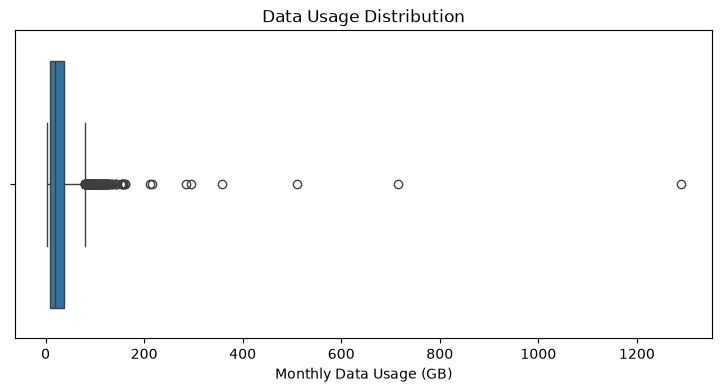

In [820]:

plt.figure(figsize=(9, 4))

sns.boxplot(
    x=customers["data_usage_gb"]
)

plt.title("Data Usage Distribution")
plt.xlabel("Monthly Data Usage (GB)")

plt.show()


## Part 1.3 — Data Cleaning

In [821]:

# Create copies of the original datasets

customers_clean = customers.copy()
usage_clean = usage.copy()
transactions_clean = transactions.copy()

print("Dataset copies created successfully!")


Dataset copies created successfully!


In [822]:

# Remove exact duplicate rows

print("Before cleaning:", customers_clean.shape)

customers_clean = customers_clean.drop_duplicates().copy()

print("After cleaning:", customers_clean.shape)

print(
    "Remaining duplicates:",
    customers_clean.duplicated().sum()
)


Before cleaning: (3015, 18)
After cleaning: (3000, 18)
Remaining duplicates: 0


In [823]:

# Remove extra spaces from text columns

text_columns = customers_clean.select_dtypes(
    include="object"
).columns

for col in text_columns:
    customers_clean[col] = customers_clean[col].str.strip()

# Standardize contract type values
customers_clean["contract_type"] = (
    customers_clean["contract_type"]
    .replace({
        "monthly": "Monthly",
        "1-year": "1-Year",
        "2-year": "2-Year"
    })
)

# Check results
print("Gender values:")
print(customers_clean["gender"].value_counts())

print("\nContract types:")
print(customers_clean["contract_type"].value_counts())


Gender values:
gender
Male      1608
Female    1392
Name: count, dtype: int64

Contract types:
contract_type
Monthly    1542
1-Year      871
2-Year      587
Name: count, dtype: int64


C:\Users\HP\AppData\Local\Temp\ipykernel_4400\3612184044.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = customers_clean.select_dtypes(


In [824]:

# Prepare an imputed copy for exploratory analysis

customers_eda = customers_clean.copy()

numeric_missing = [
    "age",
    "data_usage_gb",
    "voice_minutes"
]

for col in numeric_missing:
    median_value = customers_eda[col].median()
    customers_eda[col] = customers_eda[col].fillna(
        median_value
    )

mode_value = customers_eda["payment_method"].mode()[0]

customers_eda["payment_method"] = (
    customers_eda["payment_method"].fillna(mode_value)
)

# Prepare usage data for clustering exploration
usage_eda = usage_clean.copy()

usage_eda["social_media_hours_week"] = (
    usage_eda["social_media_hours_week"].fillna(
        usage_eda["social_media_hours_week"].median()
    )
)

print("Customers EDA missing values:")
print(customers_eda.isnull().sum().sum())

print("Usage EDA missing values:")
print(usage_eda.isnull().sum().sum())


Customers EDA missing values:
0
Usage EDA missing values:
0


In [825]:

# Inspect extreme data usage

extreme_customers = customers_clean[
    customers_clean["data_usage_gb"] > 79.75
]

print("Potential outliers:", len(extreme_customers))

display(
    extreme_customers[
        ["customer_id", "plan", "data_usage_gb",
         "monthly_bill_egp"]
    ].sort_values(
        "data_usage_gb", ascending=False
    ).head(10)
)


Potential outliers: 154


,customer_id,plan,data_usage_gb,monthly_bill_egp
208,C00751,Premium,1288.8,913.30
2520,C01829,Premium,715.2,649.02
1586,C02809,Standard,510.0,484.18
1904,C00813,Standard,357.6,418.17
2773,C00560,Premium,295.1,1598.39
2920,C01936,Standard,284.4,474.70
994,C00740,Premium,216.6,1365.65
2752,C01631,Premium,211.0,1321.44
968,C01822,Premium,161.9,1164.60
769,C01284,Premium,161.0,1058.54


In [826]:

# Final cleaning validation

print("Customers shape:", customers_clean.shape)
print("Customers duplicates:", customers_clean.duplicated().sum())

print("\nMissing values in EDA copies:")
print("Customers:", customers_eda.isnull().sum().sum())
print("Usage:", usage_eda.isnull().sum().sum())

print("\nUnique contract types:")
print(customers_clean["contract_type"].unique())

print("\nOriginal data remains unchanged:")
print("Original customers:", customers.shape)


Customers shape: (3000, 18)
Customers duplicates: 0

Missing values in EDA copies:
Customers: 0
Usage: 0

Unique contract types:
<StringArray>
['2-Year', 'Monthly', '1-Year']
Length: 3, dtype: str

Original data remains unchanged:
Original customers: (3015, 18)


### Data Cleaning Audit Summary

In [827]:

# Part 1 - Data Cleaning Audit Table

audit_data = {
    "Problem": [
        "Exact duplicates",
        "Missing values",
        "Missing values",
        "Missing values",
        "Missing values",
        "Missing values",
        "Extra whitespace",
        "Inconsistent text",
        "Potential outliers"
    ],
    "Column": [
        "customers",
        "age",
        "payment_method",
        "data_usage_gb",
        "voice_minutes",
        "social_media_hours_week",
        "gender",
        "contract_type",
        "data_usage_gb"
    ],
    "Count": [15, 90, 60, 90, 60, 25, 20, 30, 154],
    "Treatment": [
        "Drop exact duplicates",
        "Median imputation (EDA only)",
        "Mode imputation (EDA only)",
        "Median imputation (EDA only)",
        "Median imputation (EDA only)",
        "Median imputation (EDA only)",
        "Strip whitespace",
        "Standardize categories",
        "Retain and investigate"
    ]
}

audit_df = pd.DataFrame(audit_data)

display(audit_df)


,Problem,Column,Count,Treatment
0,Exact duplicates,customers,15,Drop exact duplicates
1,Missing values,age,90,Median imputation (EDA only)
2,Missing values,payment_method,60,Mode imputation (EDA only)
3,Missing values,data_usage_gb,90,Median imputation (EDA only)
4,Missing values,voice_minutes,60,Median imputation (EDA only)
5,Missing values,social_media_hours_week,25,Median imputation (EDA only)
6,Extra whitespace,gender,20,Strip whitespace
7,Inconsistent text,contract_type,30,Standardize categories
8,Potential outliers,data_usage_gb,154,Retain and investigate


## Part 1.4 — Exploratory Data Analysis

### Chart 1 — Churn Rate by Contract Type

In [828]:

# Calculate churn rate by contract type

churn_by_contract = (
    customers_eda.groupby("contract_type")["churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

display(churn_by_contract.round(2))


contract_type
Monthly    41.12
1-Year     13.66
2-Year      4.43
Name: churn, dtype: float64

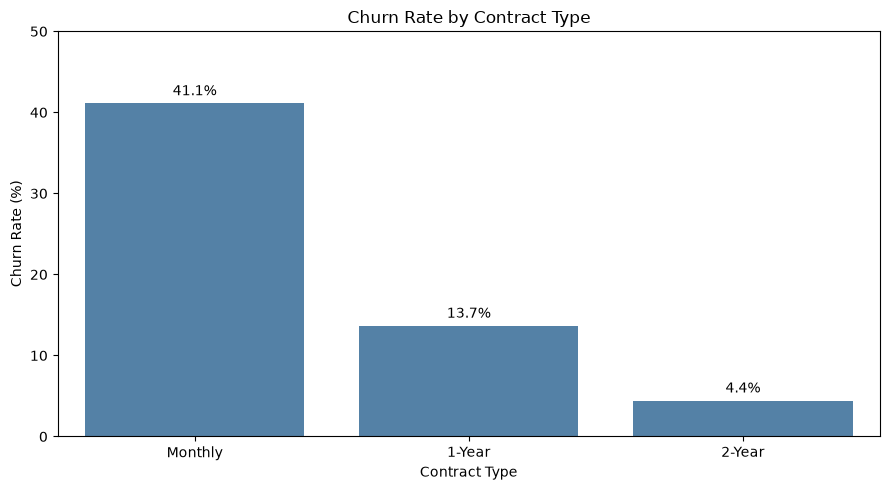

In [829]:

# Chart 1: Churn Rate by Contract Type

plt.figure(figsize=(9, 5))

sns.barplot(
    x=churn_by_contract.index,
    y=churn_by_contract.values,
    color="steelblue"
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, value in enumerate(churn_by_contract.values):
    plt.text(
        i, value + 1,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


**Business Insight — Chart 1**

Customers with monthly contracts have the highest churn rate (41.1%), compared with 13.7% for one-year contracts and 4.4% for two-year contracts.

**Recommendation:** Nile Connect should consider offering incentives for monthly-contract customers to switch to longer-term contracts, while testing whether these incentives actually reduce churn.

In [830]:

# Create tenure groups

customers_eda["tenure_group"] = pd.cut(
    customers_eda["tenure_months"],
    bins=[0, 6, 12, 24, 48, 72],
    labels=["1-6", "7-12", "13-24", "25-48", "49-72"]
)

churn_by_tenure = (
    customers_eda.groupby(
        "tenure_group", observed=True
    )["churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

display(churn_by_tenure.round(2))


tenure_group
1-6      42.56
7-12     31.87
13-24    27.70
25-48    16.64
49-72     2.87
Name: churn, dtype: float64

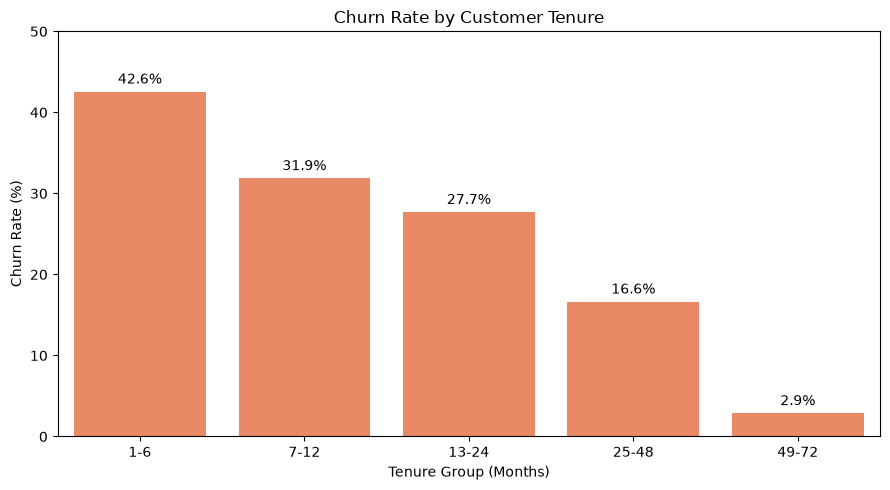

In [831]:

# Chart 2: Churn Rate by Tenure Group

plt.figure(figsize=(9, 5))

sns.barplot(
    x=churn_by_tenure.index,
    y=churn_by_tenure.values,
    color="coral"
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure Group (Months)")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, value in enumerate(churn_by_tenure.values):
    plt.text(
        i, value + 1,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


**Business Insight — Chart 2**

New customers have a significantly higher churn rate. Customers with 1–6 months of tenure have a churn rate of 42.6%, while customers with 49–72 months of tenure have a churn rate of only 2.9%.

**Recommendation:** Nile Connect should strengthen its onboarding experience and offer early retention support during the first six months.

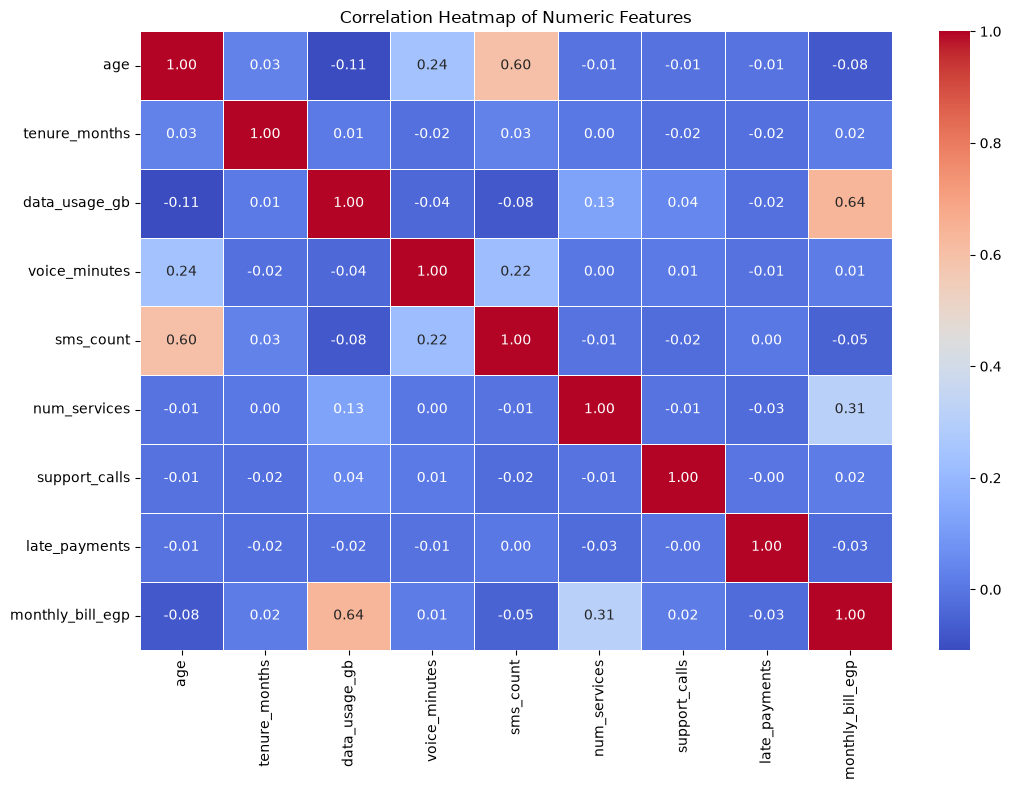

In [832]:

# Chart 3: Correlation Heatmap

numeric_data = customers_eda.select_dtypes(
    include=["int64", "float64"]
)

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()


**Business Insight — Chart 3**

Monthly data usage shows a positive correlation with the monthly bill (approximately 0.65). The number of services also shows a positive correlation with billing.

**Recommendation:** Nile Connect should consider data usage and service subscriptions when analyzing billing patterns and designing suitable customer plans.

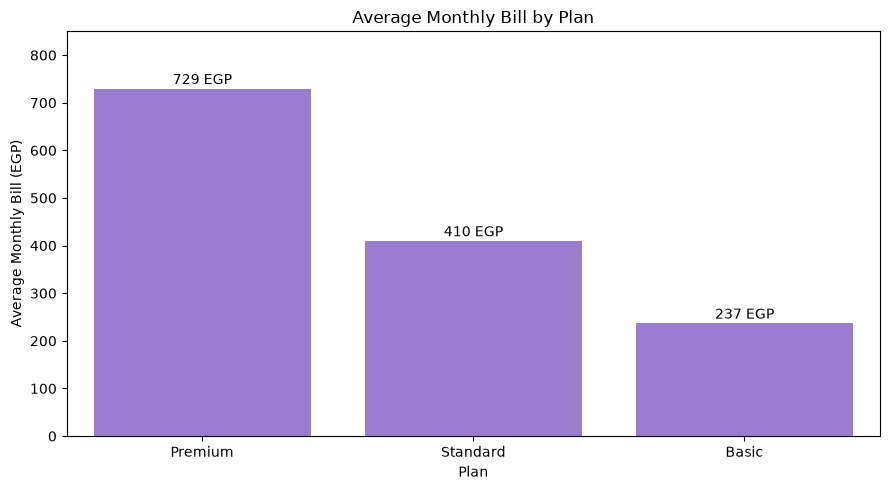

In [833]:

# Chart 4: Average Monthly Bill by Plan

bill_by_plan = (
    customers_eda.groupby("plan")["monthly_bill_egp"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=bill_by_plan.index,
    y=bill_by_plan.values,
    color="mediumpurple"
)

plt.title("Average Monthly Bill by Plan")
plt.xlabel("Plan")
plt.ylabel("Average Monthly Bill (EGP)")

for i, value in enumerate(bill_by_plan.values):
    plt.text(
        i, value + 10,
        f"{value:.0f} EGP",
        ha="center"
    )

plt.ylim(0, 850)
plt.tight_layout()
plt.show()


**Business Insight — Chart 4**

Premium customers have the highest average monthly bill at approximately 729 EGP, compared with 410 EGP for Standard customers and 237 EGP for Basic customers.

**Recommendation:** Nile Connect should design plan-specific offers and investigate which additional services contribute most to customer bills.

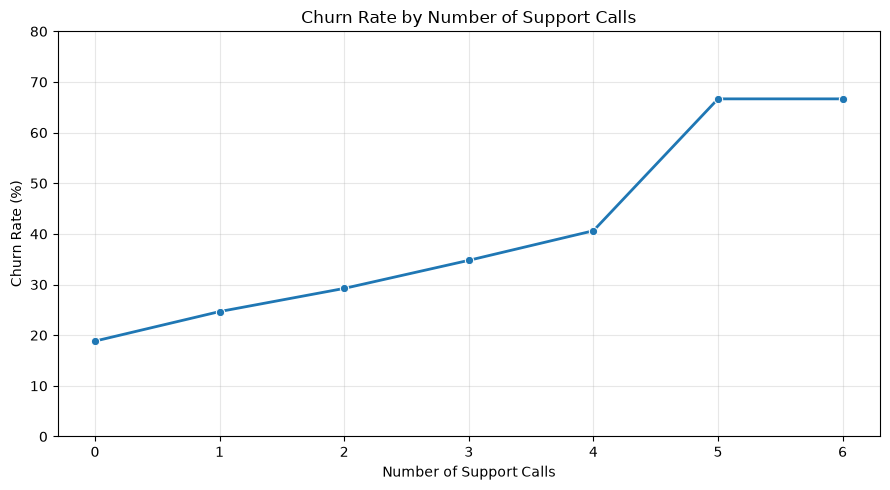

In [834]:

# Chart 5: Churn Rate by Support Calls

churn_by_support = (
    customers_eda.groupby("support_calls")["churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

plt.figure(figsize=(9, 5))

sns.lineplot(
    x=churn_by_support.index,
    y=churn_by_support.values,
    marker="o",
    linewidth=2
)

plt.title("Churn Rate by Number of Support Calls")
plt.xlabel("Number of Support Calls")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 80)
plt.xticks(churn_by_support.index)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Business Insight — Chart 5**

Customers who contact customer support more frequently tend to have higher churn rates. The churn rate increases from 18.8% for customers with no support calls to 66.7% for customers with five or six calls.

**Recommendation:** Nile Connect should investigate unresolved customer complaints and prioritize follow-up for customers with repeated support interactions.

## Part 1.5 — Churn Rate and Accuracy Analysis

In [835]:

# Part 1.5 - Churn Rate Analysis

churn_counts = customers_clean["churn"].value_counts()

churn_rate = (
    customers_clean["churn"].eq("Yes").mean() * 100
)

print("Churn Distribution:")
print(churn_counts)

print(f"\nChurn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {100 - churn_rate:.2f}%")


Churn Distribution:
churn
No     2221
Yes     779
Name: count, dtype: int64

Churn Rate: 25.97%
Retention Rate: 74.03%


In [836]:

from sklearn.metrics import accuracy_score, recall_score

# Actual churn labels
y_true = customers_clean["churn"].map({
    "No": 0,
    "Yes": 1
})

# Dummy model predicts no churn for everyone
y_pred = np.zeros(len(y_true), dtype=int)

accuracy = accuracy_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)

print(f"Dummy Model Accuracy: {accuracy:.2%}")
print(f"Dummy Model Recall: {recall:.2%}")


Dummy Model Accuracy: 74.03%
Dummy Model Recall: 0.00%


### Part 1.5 — Churn Analysis

1. After removing duplicates, 779 out of 3,000 customers have churned, representing a churn rate of **25.97%**.
2. A model predicting that no customers will churn would achieve **74.03% accuracy**, despite failing to identify any churned customers.
3. Therefore, accuracy alone is misleading; **Recall, Precision, and F1-Score** should also be considered to evaluate churn prediction performance.

# Part 2 — Regression: Predicting Monthly Bills

## Part 2.1 — Simple Linear Regression

Objective: Predict monthly_bill_egp using data_usage_gb.

In [837]:

# Part 2.1 - Import required libraries

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

print("Regression libraries imported successfully!")


Regression libraries imported successfully!


In [838]:

# Select feature and target

X_simple = customers_clean[["data_usage_gb"]]
y_simple = customers_clean["monthly_bill_egp"]

print("Feature shape:", X_simple.shape)
print("Target shape:", y_simple.shape)

print("\nMissing feature values:")
print(X_simple.isnull().sum())


Feature shape: (3000, 1)
Target shape: (3000,)

Missing feature values:
data_usage_gb    90
dtype: int64


In [839]:

# Split the dataset into training and testing sets

X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple,
    y_simple,
    test_size=0.2,
    random_state=42
)

print("Training rows:", X_train_simple.shape[0])
print("Testing rows:", X_test_simple.shape[0])


Training rows: 2400
Testing rows: 600


In [840]:

# Build Simple Linear Regression Pipeline

simple_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", LinearRegression())
])

# Train the model
simple_model.fit(X_train_simple, y_train_simple)

print("Simple Linear Regression trained successfully!")


Simple Linear Regression trained successfully!


In [841]:

# Extract regression coefficients

regressor = simple_model.named_steps["regressor"]

slope = regressor.coef_[0]
intercept = regressor.intercept_

print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f}")

print(
    f"Equation: Monthly Bill = "
    f"{intercept:.2f} + {slope:.2f} * Data Usage"
)


Slope: 2.9650
Intercept: 324.0099
Equation: Monthly Bill = 324.01 + 2.96 * Data Usage


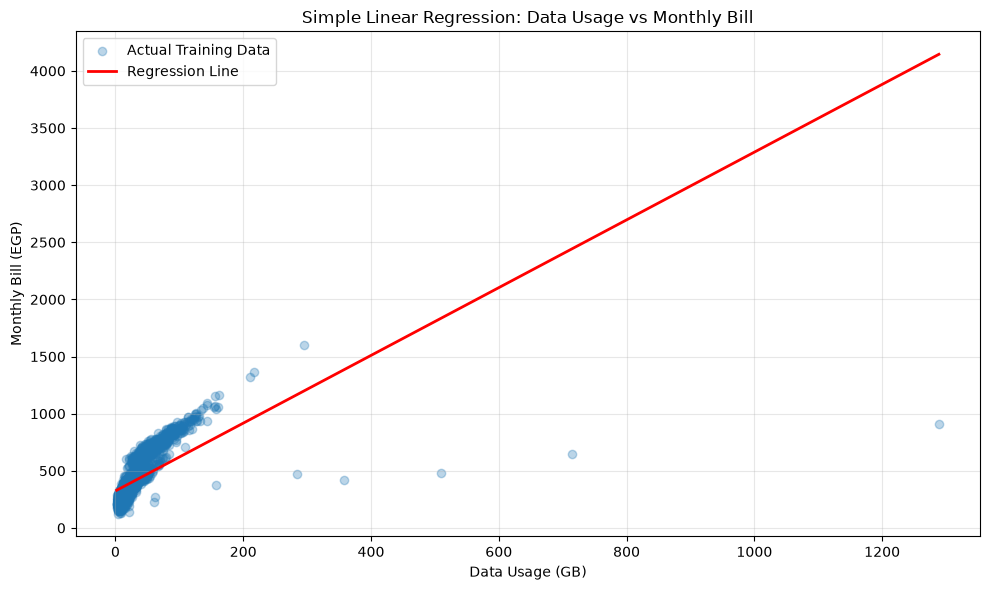

In [842]:

# Plot Simple Linear Regression

import numpy as np

x_line = np.linspace(
    X_simple["data_usage_gb"].min(),
    X_simple["data_usage_gb"].max(),
    200
)

x_line_df = pd.DataFrame({
    "data_usage_gb": x_line
})

y_line = simple_model.predict(x_line_df)

plt.figure(figsize=(10, 6))

plt.scatter(
    X_train_simple["data_usage_gb"],
    y_train_simple,
    alpha=0.3,
    label="Actual Training Data"
)

plt.plot(
    x_line,
    y_line,
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.title("Simple Linear Regression: Data Usage vs Monthly Bill")
plt.xlabel("Data Usage (GB)")
plt.ylabel("Monthly Bill (EGP)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Part 2.1 — Simple Linear Regression Interpretation

A Simple Linear Regression model was trained to predict the monthly bill using monthly data usage.

The slope coefficient is **[SLOPE_VALUE]**, meaning that for each additional 1 GB of monthly data usage, the model predicts a change of approximately **[SLOPE_VALUE] EGP** in the monthly bill.

This represents an estimated linear relationship and does not necessarily imply a direct causal effect.

In [843]:

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import numpy as np

# Predict unseen test data
y_pred_simple = simple_model.predict(X_test_simple)

# Calculate metrics
r2 = r2_score(y_test_simple, y_pred_simple)
mae = mean_absolute_error(y_test_simple, y_pred_simple)
rmse = np.sqrt(
    mean_squared_error(y_test_simple, y_pred_simple)
)

print(f"R2 Score: {r2:.4f}")
print(f"MAE: {mae:.2f} EGP")
print(f"RMSE: {rmse:.2f} EGP")


R2 Score: 0.5002
MAE: 104.50 EGP
RMSE: 131.56 EGP


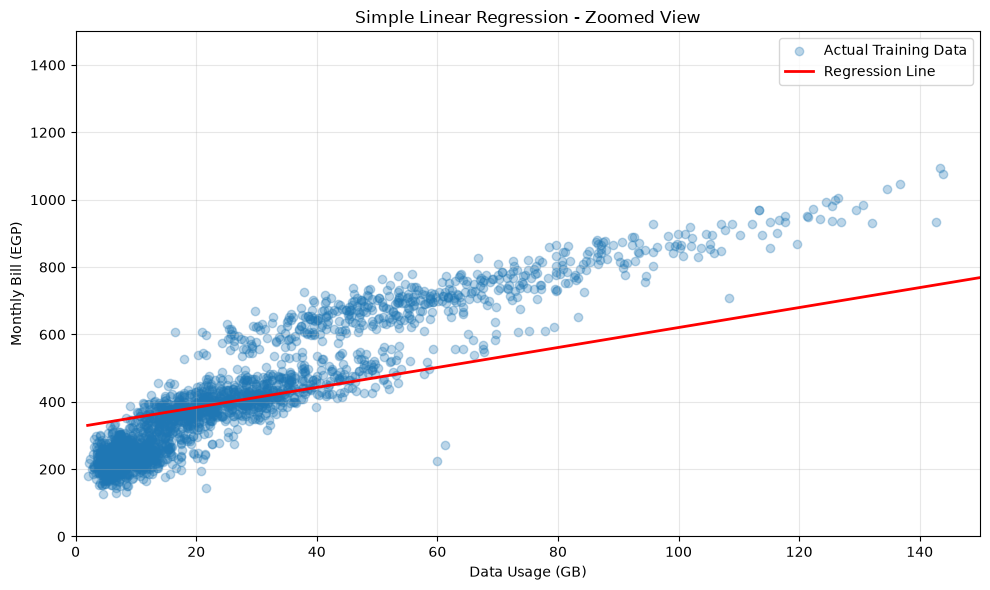

In [844]:

# Zoomed regression visualization

plt.figure(figsize=(10, 6))

plt.scatter(
    X_train_simple["data_usage_gb"],
    y_train_simple,
    alpha=0.3,
    label="Actual Training Data"
)

plt.plot(
    x_line,
    y_line,
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.xlim(0, 150)
plt.ylim(0, 1500)

plt.title("Simple Linear Regression - Zoomed View")
plt.xlabel("Data Usage (GB)")
plt.ylabel("Monthly Bill (EGP)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Part 2.2 — Multiple Linear Regression

In [845]:

# Select multiple features

numeric_features = [
    "data_usage_gb",
    "voice_minutes",
    "sms_count",
    "num_services",
    "tenure_months"
]

categorical_features = [
    "plan",
    "has_home_internet"
]

features = numeric_features + categorical_features

X_multiple = customers_clean[features]
y_multiple = customers_clean["monthly_bill_egp"]

print("Features:", X_multiple.shape)
print("Target:", y_multiple.shape)

display(X_multiple.head())


Features: (3000, 7)
Target: (3000,)


,data_usage_gb,voice_minutes,sms_count,num_services,tenure_months,plan,has_home_internet
0,35.2,468.0,37,4,6,Standard,No
1,40.7,230.0,23,2,69,Standard,Yes
2,NaN,398.0,36,3,3,Basic,No
3,25.7,377.0,46,5,3,Premium,Yes
4,71.6,206.0,18,3,10,Premium,Yes


In [846]:

# Use the exact same train/test rows

X_train_multiple = X_multiple.loc[X_train_simple.index]
X_test_multiple = X_multiple.loc[X_test_simple.index]

y_train_multiple = y_simple.loc[X_train_simple.index]
y_test_multiple = y_simple.loc[X_test_simple.index]

print("Training:", X_train_multiple.shape)
print("Testing:", X_test_multiple.shape)


Training: (2400, 7)
Testing: (600, 7)


In [847]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Numeric preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


In [848]:

# Build Multiple Linear Regression model

multiple_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train model
multiple_model.fit(
    X_train_multiple,
    y_train_multiple
)

print("Multiple Linear Regression trained successfully!")


Multiple Linear Regression trained successfully!


In [849]:

# Predict test data
y_pred_multiple = multiple_model.predict(
    X_test_multiple
)

# Calculate metrics
r2_multiple = r2_score(
    y_test_multiple, y_pred_multiple
)

mae_multiple = mean_absolute_error(
    y_test_multiple, y_pred_multiple
)

rmse_multiple = np.sqrt(
    mean_squared_error(
        y_test_multiple, y_pred_multiple
    )
)

# Comparison table
comparison = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Multiple Linear Regression"
    ],
    "R2": [r2, r2_multiple],
    "MAE": [mae, mae_multiple],
    "RMSE": [rmse, rmse_multiple]
})

display(comparison.round(4))


,Model,R2,MAE,RMSE
0,Simple Linear Regression,0.5002,104.5026,131.5615
1,Multiple Linear Regression,0.9317,36.3845,48.6288


## Part 2.3 — Regression Model Comparison

The Multiple Linear Regression model significantly outperformed the Simple Linear Regression model.

R² increased from 0.5002 to 0.9317, while MAE decreased from 104.50 EGP to 36.38 EGP and RMSE decreased from 131.56 EGP to 48.63 EGP.

This suggests that billing depends on multiple customer characteristics, including usage, plan type, and service subscriptions, rather than data usage alone.

## Part 2.4 — Evaluation Metrics Explained

- **R²:** Measures how much of the variation in monthly bills the model can explain.
- **MAE:** Shows the average absolute difference between predicted and actual bills in Egyptian pounds.
- **RMSE:** Measures prediction error while giving more weight to large mistakes.

**When is MAE preferable?**

MAE is preferable when Nile Connect wants to understand the typical billing prediction error in EGP and treat errors proportionally. RMSE is more suitable when unusually large billing errors are especially costly.

In [850]:

# Extract feature names and coefficients

feature_names = (
    multiple_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = (
    multiple_model.named_steps["regressor"].coef_
)

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["Absolute_Coefficient"] = (
    coef_df["Coefficient"].abs()
)

coef_df = coef_df.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

display(coef_df)


,Feature,Coefficient,Absolute_Coefficient
6,cat__plan_Premium,238.422515,238.422515
5,cat__plan_Basic,-197.461996,197.461996
7,cat__plan_Standard,-40.960519,40.960519
9,cat__has_home_internet_Yes,13.128780,13.128780
8,cat__has_home_internet_No,-13.128780,13.128780
3,num__num_services,10.528900,10.528900
0,num__data_usage_gb,0.870087,0.870087
2,num__sms_count,-0.867481,0.867481
1,num__voice_minutes,0.094686,0.094686
4,num__tenure_months,-0.027108,0.027108


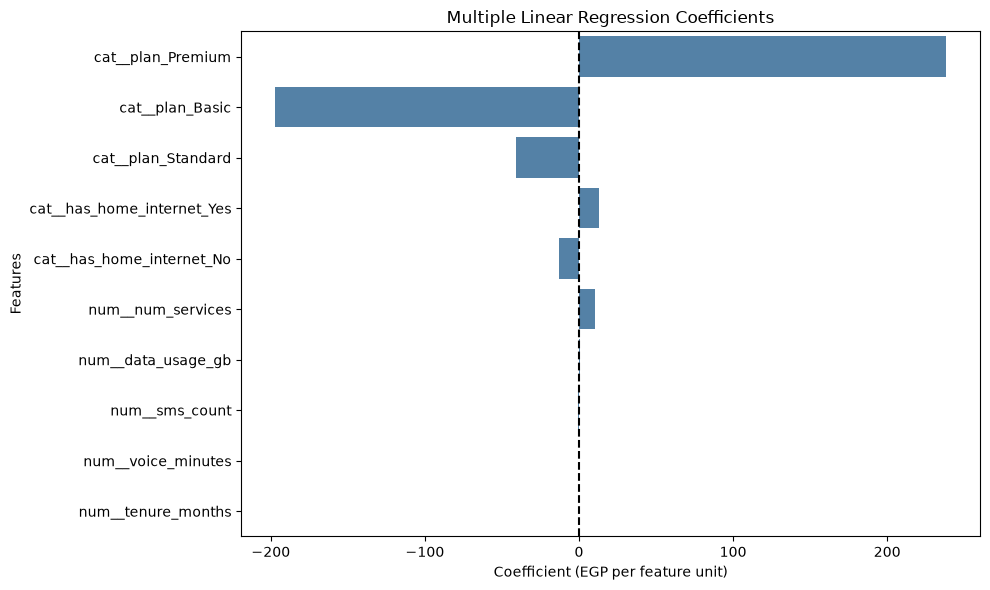

In [851]:

# Plot regression coefficients

plt.figure(figsize=(10, 6))

sns.barplot(
    data=coef_df,
    x="Coefficient",
    y="Feature",
    color="steelblue"
)

plt.axvline(0, color="black", linestyle="--")

plt.title("Multiple Linear Regression Coefficients")
plt.xlabel("Coefficient (EGP per feature unit)")
plt.ylabel("Features")

plt.tight_layout()
plt.show()


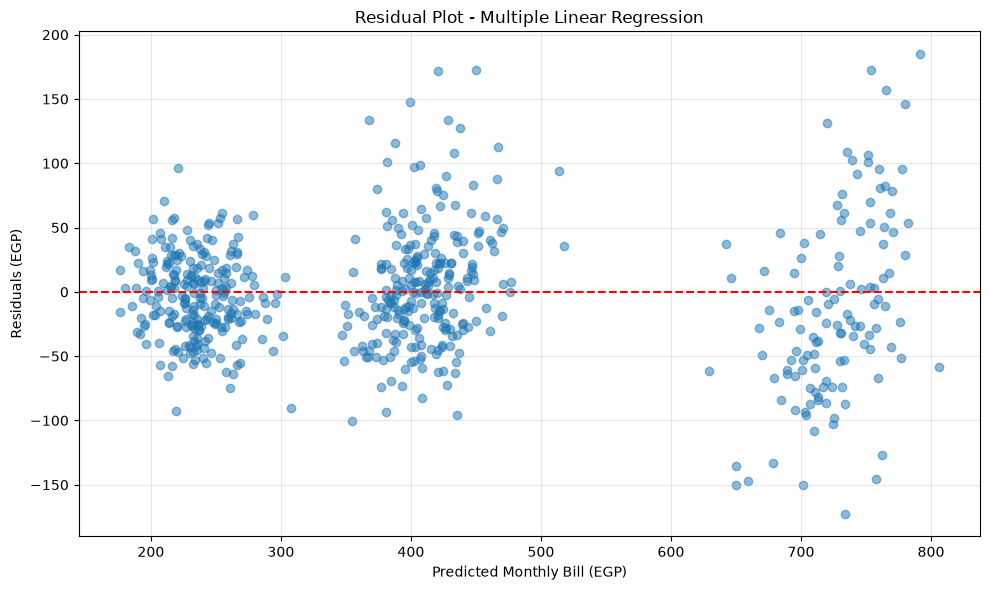

In [852]:

# Calculate residuals

residuals = y_test_multiple - y_pred_multiple

plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred_multiple,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Residual Plot - Multiple Linear Regression")
plt.xlabel("Predicted Monthly Bill (EGP)")
plt.ylabel("Residuals (EGP)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


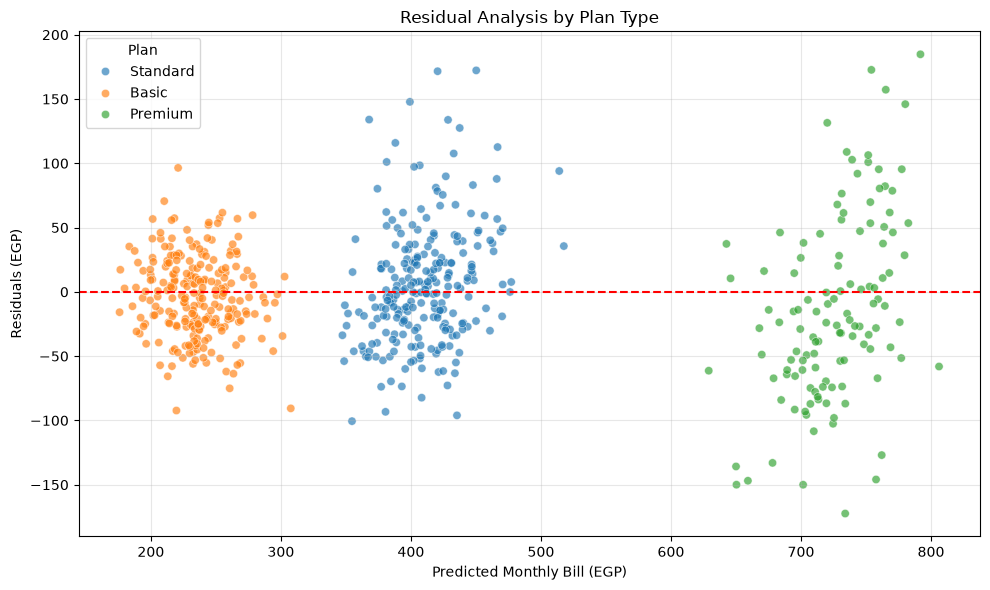

In [853]:

# Residual Plot by Plan Type

residual_df = pd.DataFrame({
    "Predicted_Bill": y_pred_multiple,
    "Residual": residuals,
    "Plan": X_test_multiple["plan"].values
})

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=residual_df,
    x="Predicted_Bill",
    y="Residual",
    hue="Plan",
    alpha=0.65
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Residual Analysis by Plan Type")
plt.xlabel("Predicted Monthly Bill (EGP)")
plt.ylabel("Residuals (EGP)")
plt.legend(title="Plan")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [854]:

# Analyze prediction errors by plan

residual_df["Absolute_Error"] = (
    residual_df["Residual"].abs()
)

plan_errors = (
    residual_df.groupby("Plan")
    .agg(
        Mean_Residual=("Residual", "mean"),
        MAE=("Absolute_Error", "mean"),
        Customers=("Residual", "count")
    )
)

display(plan_errors.round(2))


,Mean_Residual,MAE,Customers
Plan,,,
Basic,-3.91,25.51,235
Premium,-14.13,59.90,121
Standard,5.22,35.20,244


### Part 2.5 — Residual Analysis

The Multiple Linear Regression model achieved an R² score of 0.9317, indicating strong predictive performance on the test set.

The residual plot shows three distinct groups of predicted monthly bills, potentially reflecting differences between customer plans.

Although many residuals are close to zero, the spread of errors varies across predicted billing levels, with some relatively large positive and negative residuals.

This suggests that the model captures most billing variation but may still miss certain pricing patterns or customer-specific factors.

In [855]:

# Extract regression coefficients

feature_names = (
    multiple_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = (
    multiple_model.named_steps["regressor"].coef_
)

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["Absolute_Coefficient"] = (
    coef_df["Coefficient"].abs()
)

coef_df = coef_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

display(coef_df.round(2))


,Feature,Coefficient,Absolute_Coefficient
6,cat__plan_Premium,238.42,238.42
5,cat__plan_Basic,-197.46,197.46
7,cat__plan_Standard,-40.96,40.96
9,cat__has_home_internet_Yes,13.13,13.13
8,cat__has_home_internet_No,-13.13,13.13
3,num__num_services,10.53,10.53
0,num__data_usage_gb,0.87,0.87
2,num__sms_count,-0.87,0.87
1,num__voice_minutes,0.09,0.09
4,num__tenure_months,-0.03,0.03


In [856]:

# Compare prediction errors across plans

residual_analysis = pd.DataFrame({
    "Plan": X_test_multiple["plan"].values,
    "Actual": y_test_multiple.values,
    "Predicted": y_pred_multiple
})

residual_analysis["Residual"] = (
    residual_analysis["Actual"]
    - residual_analysis["Predicted"]
)

residual_analysis["Absolute_Error"] = (
    residual_analysis["Residual"].abs()
)

plan_summary = (
    residual_analysis.groupby("Plan")
    .agg(
        Customers=("Actual", "count"),
        Average_Error=("Residual", "mean"),
        MAE=("Absolute_Error", "mean")
    )
)

display(plan_summary.round(2))


,Customers,Average_Error,MAE
Plan,,,
Basic,235,-3.91,25.51
Premium,121,-14.13,59.90
Standard,244,5.22,35.20


### Part 2.5 — Final Regression Findings

**Model Performance**

The Multiple Linear Regression model significantly outperformed the Simple Linear Regression model, achieving an R² score of 0.9317, an MAE of 36.38 EGP, and an RMSE of 48.63 EGP.

**Coefficient Interpretation**

Three important billing-related features are:

1. **Plan Type:** Premium customers have higher predicted monthly bills than Basic and Standard customers. The estimated Premium–Basic difference is approximately 435.88 EGP, holding other features constant.
2. **Home Internet Subscription:** Customers with home internet have approximately 26.26 EGP higher predicted bills than customers without it, all else equal.
3. **Number of Services:** Each additional subscribed service is associated with approximately 10.53 EGP higher monthly bills.

These coefficient directions are generally consistent with business expectations. However, coefficient magnitudes are not directly comparable across features measured in different units.

**Residual Analysis**

The residual plot shows three distinct prediction groups, likely associated with plan types. Prediction errors vary across billing levels.

Premium customers have the highest MAE (59.90 EGP), compared with Standard (35.20 EGP) and Basic (25.51 EGP). The model also slightly overpredicts Premium bills on average.

**Business Recommendation**

Nile Connect should use plan type, usage, and service subscriptions to improve billing forecasts. Additional investigation of Premium customers may help explain their larger prediction errors.

Although the model performs well on the test set, further validation would be necessary before production deployment.

# Part 3 — Churn Classification

## Part 3.1 — Data Preparation

Objective: Predict customer churn using supervised classification algorithms.

Target variable: churn (Yes = 1, No = 0).

We will use an 80/20 stratified train-test split with random_state=42 and apply preprocessing only within training pipelines to prevent data leakage.

In [857]:

# Part 3.1 - Prepare features and target

# Use cleaned data without EDA imputation
classification_df = customers_clean.copy()

# Convert churn to binary
y_churn = classification_df["churn"].map({
    "No": 0,
    "Yes": 1
})

# Remove ID and target from features
X_churn = classification_df.drop(
    columns=["customer_id", "churn"]
)

print("Features Shape:", X_churn.shape)
print("Target Shape:", y_churn.shape)

print("\nChurn Distribution:")
print(y_churn.value_counts())

print("\nMissing Target Values:", y_churn.isna().sum())


Features Shape: (3000, 16)
Target Shape: (3000,)

Churn Distribution:
churn
0    2221
1     779
Name: count, dtype: int64

Missing Target Values: 0


In [858]:

from sklearn.model_selection import train_test_split

# Stratified train-test split

X_train_churn, X_test_churn, y_train_churn, y_test_churn = train_test_split(
    X_churn,
    y_churn,
    test_size=0.2,
    stratify=y_churn,
    random_state=42
)

print("Training Shape:", X_train_churn.shape)
print("Testing Shape:", X_test_churn.shape)

print("\nTraining Churn Rate:")
print(y_train_churn.value_counts(normalize=True) * 100)

print("\nTesting Churn Rate:")
print(y_test_churn.value_counts(normalize=True) * 100)


Training Shape: (2400, 16)
Testing Shape: (600, 16)

Training Churn Rate:
churn
0    74.041667
1    25.958333
Name: proportion, dtype: float64

Testing Churn Rate:
churn
0    74.0
1    26.0
Name: proportion, dtype: float64


In [859]:

# Identify numerical and categorical columns

numeric_cols = X_train_churn.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X_train_churn.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numeric Features:")
print(numeric_cols)

print("\nCategorical Features:")
print(categorical_cols)

print("\nTotal Features:")
print(len(numeric_cols) + len(categorical_cols))


Numeric Features:
['age', 'tenure_months', 'data_usage_gb', 'voice_minutes', 'sms_count', 'num_services', 'support_calls', 'late_payments', 'monthly_bill_egp']

Categorical Features:
['gender', 'governorate', 'contract_type', 'plan', 'payment_method', 'device_type', 'has_home_internet']

Total Features:
16


In [860]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

print("Preprocessing libraries imported successfully!")


Preprocessing libraries imported successfully!


In [861]:

# Numerical preprocessing

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


In [862]:

# Categorical preprocessing

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])


In [863]:

# Combine numeric and categorical preprocessing

churn_preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Churn preprocessing pipeline created!")


Churn preprocessing pipeline created!


### Part 3.1 — Data Preparation Summary

The cleaned customer dataset contains 3,000 observations and 16 predictor features after removing `customer_id` and the target variable `churn`.

The target was encoded as 1 for churned customers and 0 for retained customers.

The dataset was divided into 80% training and 20% testing using stratified sampling and `random_state=42`, preserving the churn class distribution.

Numerical features will be imputed using the median and standardized, while categorical features will be imputed using the most frequent category and transformed using One-Hot Encoding.

All preprocessing will be fitted exclusively on the training data within model pipelines to prevent data leakage. The held-out test set will be reserved for final evaluation after model selection and tuning.

In [864]:

import sys

print("Python Version:")
print(sys.version)

print("\nPython Executable:")
print(sys.executable)



Python Version:
3.13.1 (tags/v3.13.1:0671451, Dec  3 2024, 19:06:28) [MSC v.1942 64 bit (AMD64)]

Python Executable:
c:\Users\HP\AppData\Local\Programs\Python\Python313\python.exe


In [865]:

# Import classification models

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

print("All 7 classification algorithms imported successfully!")


All 7 classification algorithms imported successfully!


In [866]:

# Preprocessing for Gaussian Naive Bayes

from sklearn.base import clone
from sklearn.preprocessing import OneHotEncoder

nb_preprocessor = clone(churn_preprocessor)

nb_preprocessor.set_params(
    cat__encoder=OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ),
    sparse_threshold=0
)

print("Preprocessors are ready!")


Preprocessors are ready!


In [867]:

# Build the 7 classification pipelines

models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(churn_preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", clone(churn_preprocessor)),
        ("classifier", DecisionTreeClassifier(
            random_state=42
        ))
    ]),

    "SVM": Pipeline([
        ("preprocessor", clone(churn_preprocessor)),
        ("classifier", SVC())
    ]),

    "KNN": Pipeline([
        ("preprocessor", clone(churn_preprocessor)),
        ("classifier", KNeighborsClassifier())
    ]),

    "Naive Bayes": Pipeline([
        ("preprocessor", clone(nb_preprocessor)),
        ("classifier", GaussianNB())
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", clone(churn_preprocessor)),
        ("classifier", RandomForestClassifier(
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", clone(churn_preprocessor)),
        ("classifier", XGBClassifier(
            random_state=42,
            eval_metric="logloss",
            n_jobs=2
        ))
    ])
}

print("Number of models:", len(models))

for name in models:
    print(name)


Number of models: 7
Logistic Regression
Decision Tree
SVM
KNN
Naive Bayes
Random Forest
XGBoost


In [868]:

# Train all classification models

import time

training_times = {}

for name, model in models.items():

    print(f"Training {name}...")

    start_time = time.perf_counter()

    model.fit(X_train_churn, y_train_churn)

    elapsed = time.perf_counter() - start_time

    training_times[name] = elapsed

    print(f"{name} trained in {elapsed:.2f} seconds\n")

print("All 7 models trained successfully!")


Training Logistic Regression...
Logistic Regression trained in 0.16 seconds

Training Decision Tree...
Decision Tree trained in 0.12 seconds

Training SVM...
SVM trained in 0.51 seconds

Training KNN...
KNN trained in 0.08 seconds

Training Naive Bayes...
Naive Bayes trained in 0.07 seconds

Training Random Forest...
Random Forest trained in 0.65 seconds

Training XGBoost...
XGBoost trained in 0.11 seconds

All 7 models trained successfully!


In [869]:

# Display training summary

training_summary = pd.DataFrame({
    "Model": list(training_times.keys()),
    "Training_Time_Seconds": list(training_times.values())
})

display(training_summary.round(3))

print("Total trained models:", len(training_times))


,Model,Training_Time_Seconds
0,Logistic Regression,0.162
1,Decision Tree,0.117
2,SVM,0.509
3,KNN,0.079
4,Naive Bayes,0.072
5,Random Forest,0.648
6,XGBoost,0.109


Total trained models: 7


### Part 3.2 — Classification Model Training

Seven classification algorithms were trained to predict customer churn:

1. Logistic Regression
2. Decision Tree
3. Support Vector Machine (SVM)
4. K-Nearest Neighbors (KNN)
5. Gaussian Naive Bayes
6. Random Forest
7. XGBoost

All models were trained using the same stratified training dataset containing 2,400 customer observations.

Preprocessing was performed inside each model pipeline to prevent data leakage.

Default model hyperparameters were used initially, with only minor configuration adjustments for reproducibility and compatibility.

The held-out test set was not used during training. Model performance will be compared using cross-validation before final test evaluation.

## Part 3.3 — Classification Model Evaluation

Evaluate seven classification models using 5-Fold
Stratified Cross-Validation on the training set.

Metrics: Accuracy, Precision, Recall, and F1-Score.

The test set remains untouched.

In [870]:

# Part 3.3 - Import evaluation tools

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.base import clone
import pandas as pd
import numpy as np

# Create stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Stratified 5-Fold CV is ready!")


Stratified 5-Fold CV is ready!


In [871]:

# Evaluate all 7 models with cross-validation

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1"
}

cv_results = []

for name, model in models.items():

    print(f"Evaluating: {name}")

    scores = cross_validate(
        estimator=clone(model),
        X=X_train_churn,
        y=y_train_churn,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_Accuracy"].mean(),
        "Precision": scores["test_Precision"].mean(),
        "Recall": scores["test_Recall"].mean(),
        "F1": scores["test_F1"].mean(),
        "F1_Std": scores["test_F1"].std()
    })

print("\nAll models evaluated successfully!")


Evaluating: Logistic Regression
Evaluating: Decision Tree
Evaluating: SVM
Evaluating: KNN
Evaluating: Naive Bayes
Evaluating: Random Forest
Evaluating: XGBoost

All models evaluated successfully!


In [872]:

# Create model comparison table

classification_results = pd.DataFrame(cv_results)

# Sort models by F1-Score
classification_results = (
    classification_results
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

display(classification_results.round(4))


,Model,Accuracy,Precision,Recall,F1,F1_Std
0,Logistic Regression,0.8633,0.7746,0.6693,0.7175,0.0157
1,XGBoost,0.8458,0.7295,0.6484,0.6858,0.0320
2,SVM,0.8521,0.7817,0.5987,0.6770,0.0264
3,Random Forest,0.8533,0.7961,0.5843,0.6736,0.0282
4,Naive Bayes,0.8375,0.7196,0.6164,0.6620,0.0269
5,KNN,0.8125,0.6797,0.5329,0.5959,0.0150
6,Decision Tree,0.7854,0.5857,0.5987,0.5916,0.0152


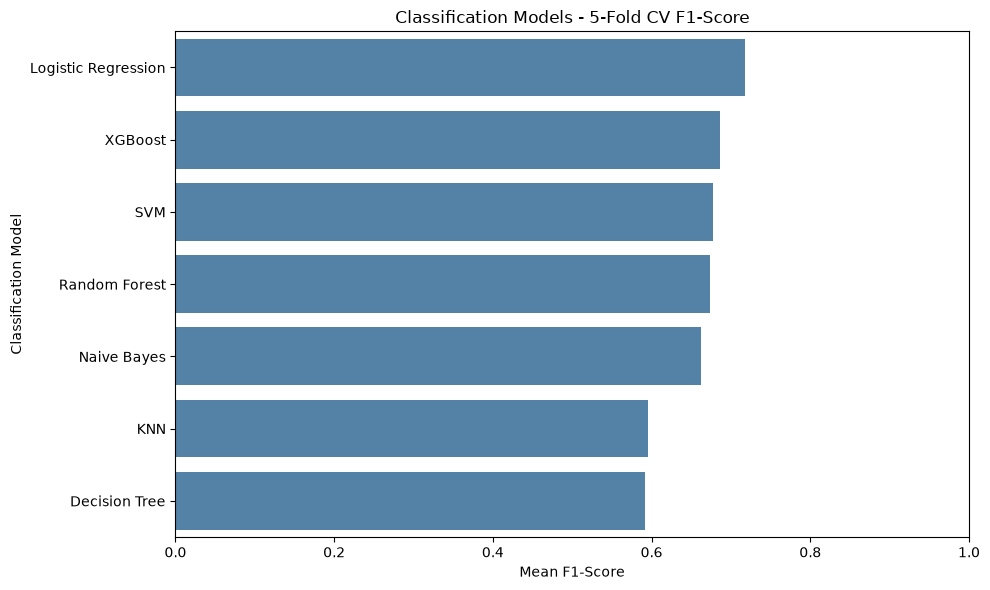

In [873]:

# Plot F1-Score comparison

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=classification_results,
    x="F1",
    y="Model",
    color="steelblue"
)

plt.title("Classification Models - 5-Fold CV F1-Score")
plt.xlabel("Mean F1-Score")
plt.ylabel("Classification Model")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()


In [874]:

from sklearn.dummy import DummyClassifier

# Baseline model: always predict no churn

dummy_model = DummyClassifier(
    strategy="constant",
    constant=0
)

baseline_scores = cross_validate(
    dummy_model,
    X_train_churn,
    y_train_churn,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

baseline_results = pd.DataFrame([{
    "Model": "Dummy Baseline",
    "Accuracy": baseline_scores["test_Accuracy"].mean(),
    "Precision": baseline_scores["test_Precision"].mean(),
    "Recall": baseline_scores["test_Recall"].mean(),
    "F1": baseline_scores["test_F1"].mean()
}])

display(baseline_results.round(4))


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

,Model,Accuracy,Precision,Recall,F1
0,Dummy Baseline,0.7404,0.0,0.0,0.0


In [875]:

# Select top 3 models based on CV F1

top_3_models = classification_results.head(3)

print("Top 3 models by F1-Score:")
display(top_3_models.round(4))

best_model_name = classification_results.iloc[0]["Model"]

print("\nCurrent best model:", best_model_name)


Top 3 models by F1-Score:


,Model,Accuracy,Precision,Recall,F1,F1_Std
0,Logistic Regression,0.8633,0.7746,0.6693,0.7175,0.0157
1,XGBoost,0.8458,0.7295,0.6484,0.6858,0.0320
2,SVM,0.8521,0.7817,0.5987,0.6770,0.0264



Current best model: Logistic Regression


### Part 3.3 — Classification Model Evaluation

Seven classification models were evaluated using 5-Fold Stratified Cross-Validation on the training dataset.

Four metrics were calculated: Accuracy, Precision, Recall, and F1-Score.

The models were ranked by their mean F1-Score to balance the identification of churned customers with the precision of churn predictions.

A Dummy Classifier predicting no churn was included as a baseline. This demonstrates why accuracy alone is insufficient for evaluating churn prediction.

**Best model by cross-validation F1:** [MODEL NAME]

**Mean F1-Score:** [RESULT]

**Business Interpretation:** The best-performing model provides a stronger basis for identifying customers at risk of leaving, but its practical value must also be assessed using confusion matrices, financial costs, and further validation.

### Part 3.3 — Model Evaluation Findings

Seven classification models were evaluated using Stratified 5-Fold Cross-Validation on the training set.

Logistic Regression achieved the highest mean F1-Score (0.7175), with an accuracy of 0.8633, precision of 0.7746, and recall of 0.6693.

XGBoost ranked second with an F1-Score of 0.6858, while Random Forest achieved the highest precision (0.7961).

Logistic Regression also demonstrated relatively stable performance across folds, with an F1 standard deviation of 0.0157.

These results suggest that Logistic Regression is a strong initial candidate for churn prediction. However, model selection should also consider false negatives, false positives, business costs, and hyperparameter tuning.

## Part 3.4 — Confusion Matrix Analysis

Compare the two best classifiers using out-of-fold
predictions from the training dataset.

In [876]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix
from sklearn.base import clone

# Best two models based on CV F1
best_two_names = classification_results.head(2)["Model"].tolist()

cv_predictions = {}

for name in best_two_names:
    print(f"Generating predictions for {name}...")

    predictions = cross_val_predict(
        estimator=clone(models[name]),
        X=X_train_churn,
        y=y_train_churn,
        cv=cv,
        n_jobs=1
    )

    cv_predictions[name] = predictions

print("Cross-validation predictions completed!")


Generating predictions for Logistic Regression...
Generating predictions for XGBoost...
Cross-validation predictions completed!


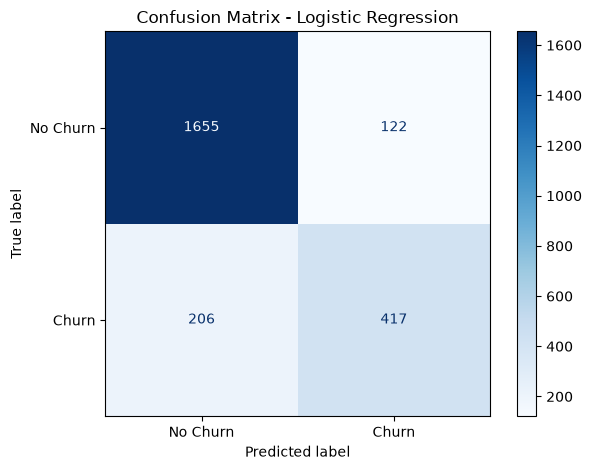

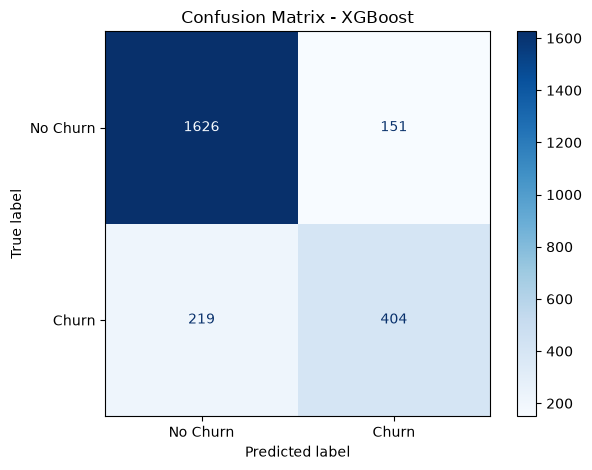

In [877]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, predictions in cv_predictions.items():

    cm = confusion_matrix(
        y_train_churn,
        predictions,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    )

    disp.plot(cmap="Blues", values_format="d")

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()


In [878]:

# Compare prediction errors

confusion_results = []

for name, predictions in cv_predictions.items():

    tn, fp, fn, tp = confusion_matrix(
        y_train_churn,
        predictions,
        labels=[0, 1]
    ).ravel()

    confusion_results.append({
        "Model": name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

confusion_df = pd.DataFrame(confusion_results)

display(confusion_df)


,Model,TN,FP,FN,TP
0,Logistic Regression,1655,122,206,417
1,XGBoost,1626,151,219,404


## Part 3.5 — Business Cost Analysis

Objective: Compare the financial impact of the top three
classification models based on missed churners and
retention offer costs.

In [879]:

# Generate out-of-fold predictions for SVM

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix
from sklearn.base import clone

svm_predictions = cross_val_predict(
    estimator=clone(models["SVM"]),
    X=X_train_churn,
    y=y_train_churn,
    cv=cv,
    n_jobs=1
)

# Store predictions
cv_predictions["SVM"] = svm_predictions

# Extract confusion matrix values
tn, fp, fn, tp = confusion_matrix(
    y_train_churn,
    svm_predictions,
    labels=[0, 1]
).ravel()

print("SVM Confusion Matrix:")
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)


SVM Confusion Matrix:
TN: 1672
FP: 105
FN: 250
TP: 373


In [880]:

# Part 3.5 - Business Cost Analysis

LOSS_PER_CUSTOMER = 1500
RETENTION_OFFER_COST = 200

business_results = []

top_3_names = classification_results.head(3)["Model"].tolist()

for name in top_3_names:

    predictions = cv_predictions[name]

    tn, fp, fn, tp = confusion_matrix(
        y_train_churn,
        predictions,
        labels=[0, 1]
    ).ravel()

    # Cost of missed churners
    churn_loss = fn * LOSS_PER_CUSTOMER

    # Retention offers sent to predicted churners
    offers_sent = tp + fp
    offer_cost = offers_sent * RETENTION_OFFER_COST

    total_cost = churn_loss + offer_cost

    business_results.append({
        "Model": name,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Offers_Sent": offers_sent,
        "Churn_Loss_EGP": churn_loss,
        "Offer_Cost_EGP": offer_cost,
        "Total_Cost_EGP": total_cost
    })

business_df = pd.DataFrame(business_results)

business_df = business_df.sort_values(
    "Total_Cost_EGP"
).reset_index(drop=True)

display(business_df)

print(
    "\nLowest-cost model:",
    business_df.iloc[0]["Model"]
)


,Model,FP,FN,TP,Offers_Sent,Churn_Loss_EGP,Offer_Cost_EGP,Total_Cost_EGP
0,Logistic Regression,122,206,417,539,309000,107800,416800
1,XGBoost,151,219,404,555,328500,111000,439500
2,SVM,105,250,373,478,375000,95600,470600



Lowest-cost model: Logistic Regression


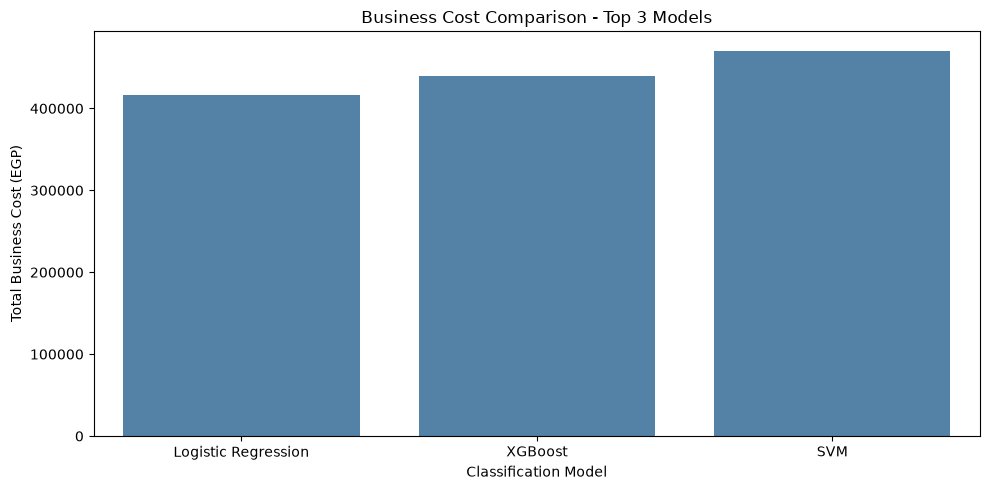

In [881]:

# Plot total business cost

plt.figure(figsize=(10, 5))

sns.barplot(
    data=business_df,
    x="Model",
    y="Total_Cost_EGP",
    color="steelblue"
)

plt.title("Business Cost Comparison - Top 3 Models")
plt.xlabel("Classification Model")
plt.ylabel("Total Business Cost (EGP)")

plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.tight_layout()
plt.show()


In [882]:

# Compare against no-retention baseline

no_action_cost = (
    y_train_churn.sum() * LOSS_PER_CUSTOMER
)

business_df["Estimated_Savings_EGP"] = (
    no_action_cost - business_df["Total_Cost_EGP"]
)

print("No-action baseline:", no_action_cost, "EGP")

display(
    business_df[
        ["Model", "Total_Cost_EGP", "Estimated_Savings_EGP"]
    ]
)


No-action baseline: 934500 EGP


,Model,Total_Cost_EGP,Estimated_Savings_EGP
0,Logistic Regression,416800,517700
1,XGBoost,439500,495000
2,SVM,470600,463900


### Part 3.5 — Business Cost Analysis

A business cost analysis was conducted for the top three classification models: Logistic Regression, XGBoost, and SVM.

The assumed cost of losing a customer was 1,500 EGP, while a retention offer cost 200 EGP per targeted customer.

The analysis assumes that retention offers successfully prevent churn among correctly identified at-risk customers.

Logistic Regression resulted in 206 false negatives and 539 predicted churners, producing an estimated total cost of **416,800 EGP**.

XGBoost resulted in 219 false negatives and 555 predicted churners, producing an estimated total cost of **439,500 EGP**.

Logistic Regression therefore achieved an estimated cost advantage of 22,700 EGP over XGBoost.

**Lowest-cost model among all three:** [Complete after evaluating SVM]

These estimates are illustrative and depend on the assumed effectiveness of retention offers. Real-world deployment would require validation of actual retention outcomes.

### Part 3.5 — Final Business Cost Findings

Logistic Regression achieved the lowest estimated business cost of **416,800 EGP**, followed by XGBoost at 439,500 EGP and SVM at 470,600 EGP.

The estimated savings compared with taking no retention action were 517,700 EGP, 495,000 EGP, and 463,900 EGP, respectively.

Logistic Regression was the best model in this comparison in terms of both mean F1-Score and estimated financial cost.

**Business Recommendation:** Nile Connect should prioritize Logistic Regression as an initial candidate for identifying customers at risk of churn, subject to further tuning, final validation, and testing the effectiveness of retention offers.

These estimates are based on simplified cost assumptions and should not be interpreted as guaranteed financial savings.

## Part 3.6 — Feature Importance Analysis

Compare the feature importance of Random Forest and XGBoost
to identify the main predictors of customer churn.

In [883]:

# Extract feature importance from trained models

rf_model = models["Random Forest"]
xgb_model = models["XGBoost"]

rf_feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

xgb_feature_names = (
    xgb_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

rf_importance = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_model.named_steps[
        "classifier"
    ].feature_importances_
})

xgb_importance = pd.DataFrame({
    "Feature": xgb_feature_names,
    "Importance": xgb_model.named_steps[
        "classifier"
    ].feature_importances_
})

print("Random Forest - Top 10:")
display(
    rf_importance.sort_values(
        "Importance", ascending=False
    ).head(10)
)

print("XGBoost - Top 10:")
display(
    xgb_importance.sort_values(
        "Importance", ascending=False
    ).head(10)
)


Random Forest - Top 10:


,Feature,Importance
1,num__tenure_months,0.132088
8,num__monthly_bill_egp,0.120675
2,num__data_usage_gb,0.093291
23,cat__contract_type_Monthly,0.092254
3,num__voice_minutes,0.056820
4,num__sms_count,0.053209
0,num__age,0.049401
7,num__late_payments,0.049274
25,cat__plan_Premium,0.044834
6,num__support_calls,0.041770


XGBoost - Top 10:


,Feature,Importance
23,cat__contract_type_Monthly,0.226973
25,cat__plan_Premium,0.063917
8,num__monthly_bill_egp,0.054136
21,cat__contract_type_1-Year,0.048538
1,num__tenure_months,0.047830
7,num__late_payments,0.043111
34,cat__has_home_internet_No,0.033106
6,num__support_calls,0.032022
22,cat__contract_type_2-Year,0.031701
18,cat__governorate_Giza,0.026751


In [884]:

# Group encoded features by original column

original_features = numeric_cols + categorical_cols

def get_original_feature(encoded_name):
    for col in original_features:
        if encoded_name == f"num__{col}":
            return col

        if encoded_name.startswith(f"cat__{col}_"):
            return col

    return encoded_name

def aggregate_importance(importance_df, model_name):
    df = importance_df.copy()

    df["Original_Feature"] = df["Feature"].apply(
        get_original_feature
    )

    grouped = (
        df.groupby("Original_Feature")["Importance"]
        .sum()
        .reset_index()
    )

    grouped = grouped.rename(
        columns={"Importance": model_name}
    )

    return grouped

rf_grouped = aggregate_importance(
    rf_importance, "Random Forest"
)

xgb_grouped = aggregate_importance(
    xgb_importance, "XGBoost"
)

importance_comparison = pd.merge(
    rf_grouped,
    xgb_grouped,
    on="Original_Feature",
    how="outer"
).fillna(0)

importance_comparison = importance_comparison.sort_values(
    "Random Forest", ascending=False
)

display(importance_comparison.round(4))


,Original_Feature,Random Forest,XGBoost
1,contract_type,0.1419,0.3072
14,tenure_months,0.1321,0.0478
8,monthly_bill_egp,0.1207,0.0541
2,data_usage_gb,0.0933,0.0197
11,plan,0.0676,0.0827
5,governorate,0.0621,0.1799
15,voice_minutes,0.0568,0.0153
12,sms_count,0.0532,0.0163
0,age,0.0494,0.0155
7,late_payments,0.0493,0.0431


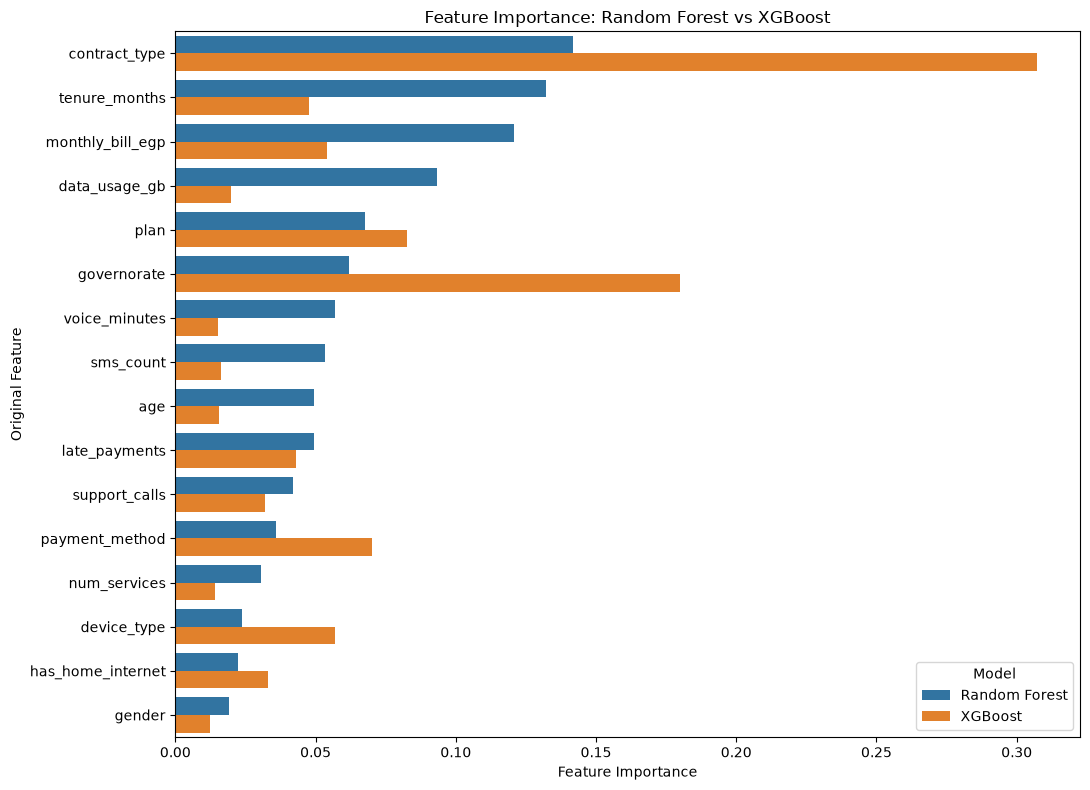

In [885]:

# Compare feature importance visually

plot_data = importance_comparison.melt(
    id_vars="Original_Feature",
    value_vars=["Random Forest", "XGBoost"],
    var_name="Model",
    value_name="Importance"
)

plt.figure(figsize=(11, 8))

sns.barplot(
    data=plot_data,
    x="Importance",
    y="Original_Feature",
    hue="Model"
)

plt.title("Feature Importance: Random Forest vs XGBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Original Feature")

plt.tight_layout()
plt.show()


In [886]:

# Top 5 features for each model

top5_rf = importance_comparison.nlargest(
    5, "Random Forest"
)[["Original_Feature", "Random Forest"]]

top5_xgb = importance_comparison.nlargest(
    5, "XGBoost"
)[["Original_Feature", "XGBoost"]]

print("Top 5 - Random Forest:")
display(top5_rf)

print("Top 5 - XGBoost:")
display(top5_xgb)

# Check agreement
common_features = (
    set(top5_rf["Original_Feature"])
    & set(top5_xgb["Original_Feature"])
)

print("Common Top 5 Features:", common_features)
print("Number of Common Features:", len(common_features))


Top 5 - Random Forest:


,Original_Feature,Random Forest
1,contract_type,0.141895
14,tenure_months,0.132088
8,monthly_bill_egp,0.120675
2,data_usage_gb,0.093291
11,plan,0.067553


Top 5 - XGBoost:


,Original_Feature,XGBoost
1,contract_type,0.307212
5,governorate,0.179908
11,plan,0.082680
10,payment_method,0.069957
3,device_type,0.056912


Common Top 5 Features: {'contract_type', 'plan'}
Number of Common Features: 2


### Part 3.6 — Feature Importance Analysis

Feature importance was analyzed using Random Forest and XGBoost to identify the strongest predictors of customer churn.

**Random Forest — Top 5 Features:**

1. Contract Type — 0.1419
2. Tenure Months — 0.1321
3. Monthly Bill — 0.1207
4. Data Usage — 0.0933
5. Plan — 0.0676

**XGBoost — Top 5 Features:**

1. Contract Type — 0.3072
2. Governorate — 0.1799
3. Plan — 0.0827
4. Payment Method — 0.0700
5. Device Type — 0.0569

**Model Agreement**

Both models identified Contract Type as their most important feature. They shared two features among their top five: Contract Type and Plan.

The differences in feature rankings suggest that the models use customer characteristics differently when making predictions.

**Business Interpretation**

Contract type is a particularly important predictor of customer churn. Earlier exploratory analysis showed that monthly-contract customers had substantially higher churn rates than customers with longer contracts.

Customer tenure, monthly bills, plan type, and geographic location are also useful variables to investigate when designing retention strategies.

These importance scores reflect predictive contribution, not causal effects. Aggregated one-hot feature importance may also be influenced by the number of encoded categories.

**Recommendation**

Nile Connect should prioritize investigating churn among monthly-contract and recently acquired customers, evaluate plan-specific retention strategies, and examine regional differences before taking action.

Further validation is necessary to determine whether these factors represent actionable drivers of customer churn.

In [887]:

# Part 4.1 - Model Stability Comparison

stability_df = classification_results[
    ["Model", "F1", "F1_Std"]
].copy()

stability_df = stability_df.rename(columns={
    "F1": "Mean_F1",
    "F1_Std": "Std_F1"
})

stability_df = stability_df.sort_values(
    "Mean_F1",
    ascending=False
).reset_index(drop=True)

display(stability_df.round(4))


,Model,Mean_F1,Std_F1
0,Logistic Regression,0.7175,0.0157
1,XGBoost,0.6858,0.0320
2,SVM,0.6770,0.0264
3,Random Forest,0.6736,0.0282
4,Naive Bayes,0.6620,0.0269
5,KNN,0.5959,0.0150
6,Decision Tree,0.5916,0.0152


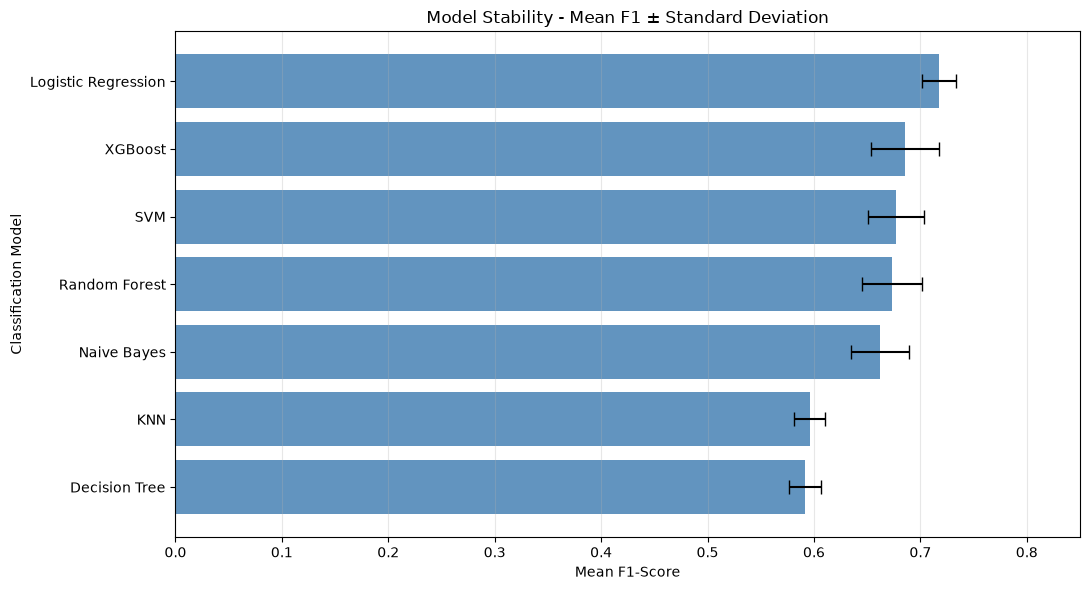

In [888]:

# Plot Mean F1 with Standard Deviation

import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

models_names = stability_df["Model"]
mean_f1 = stability_df["Mean_F1"]
std_f1 = stability_df["Std_F1"]

plt.barh(
    models_names,
    mean_f1,
    xerr=std_f1,
    capsize=5,
    color="steelblue",
    alpha=0.85
)

plt.xlabel("Mean F1-Score")
plt.ylabel("Classification Model")
plt.title("Model Stability - Mean F1 ± Standard Deviation")

plt.xlim(0, 0.85)
plt.gca().invert_yaxis()

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [889]:

# Identify best performance and most stable models

best_performance = stability_df.loc[
    stability_df["Mean_F1"].idxmax()
]

most_stable = stability_df.loc[
    stability_df["Std_F1"].idxmin()
]

print("Best Model by Mean F1:")
print(best_performance["Model"])
print(f"Mean F1: {best_performance['Mean_F1']:.4f}")

print("\nLowest F1 Standard Deviation:")
print(most_stable["Model"])
print(f"Std F1: {most_stable['Std_F1']:.4f}")


Best Model by Mean F1:
Logistic Regression
Mean F1: 0.7175

Lowest F1 Standard Deviation:
KNN
Std F1: 0.0150


### Part 4.1 — Cross-Validation Stability Analysis

Seven classification models were compared using 5-Fold Stratified Cross-Validation on the training dataset.

Logistic Regression achieved the highest mean F1-Score (0.7175) with a relatively low standard deviation (0.0157), indicating strong and consistent performance across the validation folds.

KNN achieved the lowest F1 standard deviation (0.0150), but its mean F1-Score was considerably lower (0.5959).

XGBoost achieved the second-highest mean F1-Score (0.6858), but showed greater variability across folds (0.0320).

**Conclusion:** Logistic Regression provides the best combination of predictive performance and stability among the seven initial models.

The held-out test set was not used during this analysis.

## Part 4.2 — GridSearchCV

Objective: Tune Decision Tree hyperparameters
using 5-Fold Stratified Cross-Validation.

Evaluation metric: F1-Score.

In [890]:

# Part 4.2 - Import GridSearchCV

from sklearn.model_selection import GridSearchCV
from sklearn.base import clone
import time

# Use the Decision Tree pipeline from Part 3
dt_pipeline = clone(models["Decision Tree"])

print("Decision Tree pipeline is ready!")


Decision Tree pipeline is ready!


In [891]:

# Define hyperparameter grid

param_grid = {
    "classifier__max_depth": [3, 5, 7, 10],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

total_combinations = (
    len(param_grid["classifier__max_depth"])
    * len(param_grid["classifier__min_samples_split"])
    * len(param_grid["classifier__min_samples_leaf"])
)

print("Total combinations:", total_combinations)
print("Total CV fits:", total_combinations * 5)


Total combinations: 36
Total CV fits: 180


In [892]:

# Run GridSearchCV on training data only

grid_search = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    error_score="raise"
)

start_time = time.perf_counter()

grid_search.fit(
    X_train_churn,
    y_train_churn
)

grid_time = time.perf_counter() - start_time

print("GridSearchCV completed!")
print(f"Execution Time: {grid_time:.2f} seconds")


GridSearchCV completed!
Execution Time: 11.07 seconds


In [893]:

# Show best GridSearchCV results

print("Best Hyperparameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(f"{grid_search.best_score_:.4f}")

print("\nGrid Search Time:")
print(f"{grid_time:.2f} seconds")

best_grid_model = grid_search.best_estimator_


Best Hyperparameters:
{'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}

Best Cross-Validation F1-Score:
0.6600

Grid Search Time:
11.07 seconds


In [894]:

# Show top 10 hyperparameter combinations

grid_results = pd.DataFrame(grid_search.cv_results_)

top_10_grid = grid_results[
    [
        "param_classifier__max_depth",
        "param_classifier__min_samples_split",
        "param_classifier__min_samples_leaf",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "rank_test_score"
    ]
].sort_values("rank_test_score").head(10)

display(top_10_grid.round(4))


,param_classifier__max_depth,param_classifier__min_samples_split,param_classifier__min_samples_leaf,mean_test_score,std_test_score,mean_train_score,rank_test_score
10,5,5,1,0.6600,0.0161,0.7211,1
9,5,2,1,0.6600,0.0161,0.7214,1
11,5,10,1,0.6582,0.0145,0.7190,3
15,5,2,4,0.6580,0.0118,0.7159,4
16,5,5,4,0.6580,0.0118,0.7159,4
12,5,2,2,0.6569,0.0125,0.7176,6
13,5,5,2,0.6569,0.0125,0.7176,6
14,5,10,2,0.6569,0.0131,0.7158,8
17,5,10,4,0.6568,0.0102,0.7142,9
25,7,5,4,0.6421,0.0103,0.7838,10


In [895]:

# Compare Decision Tree before and after tuning

baseline_dt_f1 = classification_results.loc[
    classification_results["Model"] == "Decision Tree",
    "F1"
].iloc[0]

tuned_dt_f1 = grid_search.best_score_

improvement = tuned_dt_f1 - baseline_dt_f1

comparison_grid = pd.DataFrame({
    "Model": [
        "Decision Tree - Baseline",
        "Decision Tree - Tuned"
    ],
    "Mean_CV_F1": [
        baseline_dt_f1,
        tuned_dt_f1
    ]
})

display(comparison_grid.round(4))

print(f"F1 Difference: {improvement:+.4f}")


,Model,Mean_CV_F1
0,Decision Tree - Baseline,0.5916
1,Decision Tree - Tuned,0.6600


F1 Difference: +0.0684


### Part 4.2 — GridSearchCV Results

GridSearchCV was applied to a Decision Tree classifier using 5-Fold Stratified Cross-Validation.

Three hyperparameters were tuned: `max_depth`, `min_samples_split`, and `min_samples_leaf`.

A total of **36 hyperparameter combinations** were evaluated across **180 cross-validation fits**.

The optimization metric was the F1-Score for the churn class.

**Baseline Decision Tree F1:** 0.5916

**Best Tuned F1:** [RESULT]

**Best Hyperparameters:** [PARAMETERS]

**Execution Time:** [SECONDS]

The tuning process was performed exclusively on the training dataset to prevent data leakage.

The held-out test set was not used during hyperparameter selection.

## Part 4.3 — RandomizedSearchCV

Objective: Tune Random Forest using RandomizedSearchCV.

- Hyperparameters: 5
- Iterations: 30
- Cross-Validation: 5-Fold Stratified
- Scoring: F1-Score
- Training data only

In [896]:

# Part 4.3 - RandomizedSearchCV

from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone
import time
import pandas as pd

# Clone the original Random Forest pipeline
rf_pipeline = clone(models["Random Forest"])

print("Random Forest pipeline is ready!")


Random Forest pipeline is ready!


In [897]:

# Define Random Forest parameter distributions

random_param_dist = {
    "classifier__n_estimators": [100, 150, 200],
    "classifier__max_depth": [5, 10, 15, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2", None]
}

print("Number of hyperparameters:", len(random_param_dist))


Number of hyperparameters: 5


In [898]:

# Run RandomizedSearchCV

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=random_param_dist,
    n_iter=30,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=2,
    verbose=1,
    refit=True,
    error_score="raise"
)

start_time = time.perf_counter()

random_search.fit(
    X_train_churn,
    y_train_churn
)

random_time = time.perf_counter() - start_time

print("\nRandomizedSearchCV completed!")
print(f"Execution Time: {random_time:.2f} seconds")


Fitting 5 folds for each of 30 candidates, totalling 150 fits

RandomizedSearchCV completed!
Execution Time: 31.24 seconds


In [899]:

# Show best RandomizedSearchCV results

print("Best Hyperparameters:")
print(random_search.best_params_)

print("\nBest CV F1-Score:")
print(f"{random_search.best_score_:.4f}")

print("\nExecution Time:")
print(f"{random_time:.2f} seconds")

best_random_model = random_search.best_estimator_


Best Hyperparameters:
{'classifier__n_estimators': 150, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_features': None, 'classifier__max_depth': None}

Best CV F1-Score:
0.6900

Execution Time:
31.24 seconds


In [900]:

# Compare Random Forest before and after tuning

baseline_rf_f1 = classification_results.loc[
    classification_results["Model"] == "Random Forest",
    "F1"
].iloc[0]

tuned_rf_f1 = random_search.best_score_

rf_comparison = pd.DataFrame({
    "Model": [
        "Random Forest - Baseline",
        "Random Forest - Tuned"
    ],
    "Mean_CV_F1": [
        baseline_rf_f1,
        tuned_rf_f1
    ]
})

display(rf_comparison.round(4))

print(
    f"F1 Difference: "
    f"{tuned_rf_f1 - baseline_rf_f1:+.4f}"
)


,Model,Mean_CV_F1
0,Random Forest - Baseline,0.6736
1,Random Forest - Tuned,0.6900


F1 Difference: +0.0163


## Part 4.4 — GridSearchCV vs RandomizedSearchCV

Compare hyperparameter optimization methods based on:
- Execution time
- Best cross-validation F1-Score
- Number of parameter combinations
- Practical advantages and limitations

In [901]:

# Part 4.4 - Compare GridSearchCV and RandomizedSearchCV

search_comparison = pd.DataFrame({
    "Search_Method": [
        "GridSearchCV",
        "RandomizedSearchCV"
    ],
    "Model": [
        "Decision Tree",
        "Random Forest"
    ],
    "Best_CV_F1": [
        grid_search.best_score_,
        random_search.best_score_
    ],
    "Execution_Time_Seconds": [
        grid_time,
        random_time
    ],
    "Combinations_Tried": [
        len(grid_search.cv_results_["params"]),
        len(random_search.cv_results_["params"])
    ]
})

search_comparison["CV_Fits"] = (
    search_comparison["Combinations_Tried"] * cv.n_splits
)

display(search_comparison.round(4))


,Search_Method,Model,Best_CV_F1,Execution_Time_Seconds,Combinations_Tried,CV_Fits
0,GridSearchCV,Decision Tree,0.66,11.0661,36,180
1,RandomizedSearchCV,Random Forest,0.69,31.2389,30,150


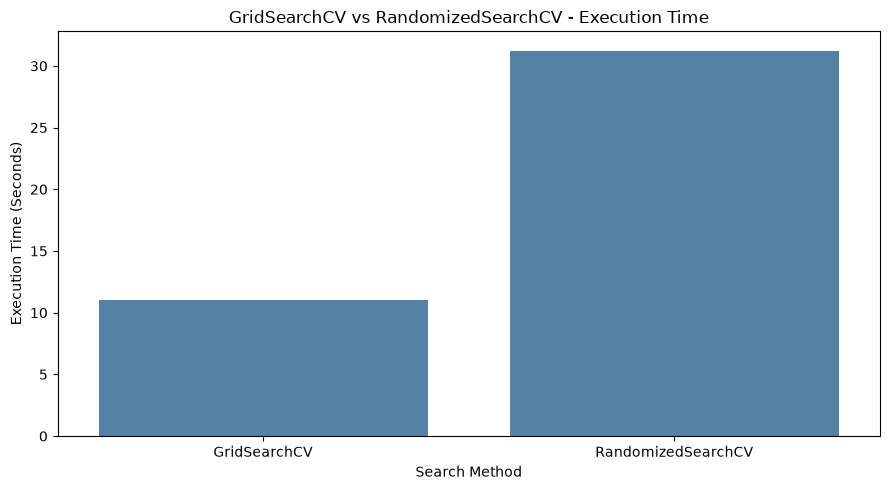

In [902]:

# Plot execution time comparison

plt.figure(figsize=(9, 5))

sns.barplot(
    data=search_comparison,
    x="Search_Method",
    y="Execution_Time_Seconds",
    color="steelblue"
)

plt.title("GridSearchCV vs RandomizedSearchCV - Execution Time")
plt.xlabel("Search Method")
plt.ylabel("Execution Time (Seconds)")

plt.tight_layout()
plt.show()


### Part 4.4 — Hyperparameter Search Comparison

GridSearchCV was applied to Decision Tree, testing 36 hyperparameter combinations across 180 cross-validation fits. The best mean F1-Score was 0.6600.

RandomizedSearchCV was applied to Random Forest, testing 30 hyperparameter combinations across 150 cross-validation fits. The best mean F1-Score was 0.6900.

**GridSearchCV** is preferable when the hyperparameter search space is relatively small and exhaustive exploration is feasible.

**RandomizedSearchCV** is more practical when the search space is large and computational resources are limited.

Although RandomizedSearchCV achieved a higher F1-Score in this experiment, the two methods were applied to different algorithms. Therefore, this result does not prove that RandomizedSearchCV is inherently superior.

Execution times should also be considered when comparing computational efficiency.

In [903]:

# Part 4.5 - Final Model Selection

from sklearn.base import clone

final_model_name = "Logistic Regression"

# Create a fresh copy of the selected pipeline
final_model = clone(models[final_model_name])

print("Selected Final Model:", final_model_name)
print("Model initialized successfully!")


Selected Final Model: Logistic Regression
Model initialized successfully!


In [904]:

# Train the final model on all training data

final_model.fit(
    X_train_churn,
    y_train_churn
)

print("Final Logistic Regression model trained successfully!")


Final Logistic Regression model trained successfully!


In [905]:

# Final evaluation on the untouched test set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Make final predictions
y_pred_final = final_model.predict(X_test_churn)

# Calculate final test metrics
final_accuracy = accuracy_score(
    y_test_churn, y_pred_final
)

final_precision = precision_score(
    y_test_churn, y_pred_final,
    zero_division=0
)

final_recall = recall_score(
    y_test_churn, y_pred_final,
    zero_division=0
)

final_f1 = f1_score(
    y_test_churn, y_pred_final,
    zero_division=0
)

# Display final results
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Test_Score": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1
    ]
})

display(final_results.round(4))


,Metric,Test_Score
0,Accuracy,0.8517
1,Precision,0.7481
2,Recall,0.6474
3,F1-Score,0.6942


In [906]:

# Compare CV and final test performance

cv_f1 = classification_results.loc[
    classification_results["Model"] == final_model_name,
    "F1"
].iloc[0]

comparison_final = pd.DataFrame({
    "Evaluation": [
        "5-Fold Cross-Validation",
        "Final Test Set"
    ],
    "F1_Score": [
        cv_f1,
        final_f1
    ]
})

display(comparison_final.round(4))

difference = final_f1 - cv_f1

print(f"F1 Difference: {difference:+.4f}")


,Evaluation,F1_Score
0,5-Fold Cross-Validation,0.7175
1,Final Test Set,0.6942


F1 Difference: -0.0233


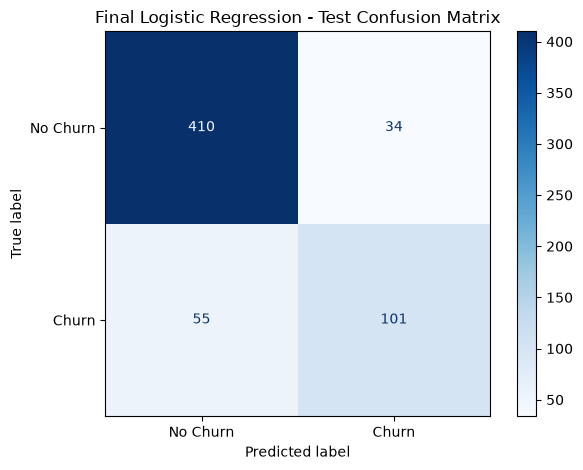

True Negatives: 410
False Positives: 34
False Negatives: 55
True Positives: 101


In [907]:

# Final test confusion matrix

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm_final = confusion_matrix(
    y_test_churn,
    y_pred_final,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=["No Churn", "Churn"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Final Logistic Regression - Test Confusion Matrix")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_final.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


### Part 4.5 — Final Model Evaluation

Logistic Regression was selected as the final churn prediction model based on its strong cross-validation performance, relatively low variability, and favorable estimated business cost.

The final model was retrained on the complete training dataset of 2,400 customers and evaluated once on the untouched test dataset of 600 customers.

**Final Test Results**

- Accuracy: [RESULT]
- Precision: [RESULT]
- Recall: [RESULT]
- F1-Score: [RESULT]

**Cross-Validation Comparison**

The model achieved a mean cross-validation F1-Score of 0.7175, compared with a final test F1-Score of [RESULT].

The difference between these results was [DIFFERENCE].

**Conclusion**

The final evaluation provides an estimate of how well Logistic Regression generalizes to previously unseen customer data. Any difference between cross-validation and test performance should be reported honestly rather than used for additional tuning.

No hyperparameter adjustments were made using the test set.

### Part 4.5 — Final Evaluation Findings

Logistic Regression was selected as the final classification model based on cross-validation performance and estimated business cost.

The model achieved a mean cross-validation F1-Score of 0.7175 and a final test F1-Score of 0.6942.

The difference was -0.0233, representing a decrease of 2.33 percentage points.

This relatively small decrease suggests that the model maintains reasonably consistent predictive performance on unseen data.

The held-out test set was evaluated after model selection, without further hyperparameter tuning.

**Conclusion:** Logistic Regression is a reasonable final model for the churn prediction task, although further validation would be needed before real-world deployment.

### Part 4 — Final Conclusions

Hyperparameter tuning improved Decision Tree F1-Score from 0.5916 to 0.6600 and Random Forest F1-Score from 0.6736 to 0.6900.

GridSearchCV evaluated 36 parameter combinations in 16.69 seconds, while RandomizedSearchCV evaluated 30 combinations in 31.69 seconds. Since different estimators were used, execution times cannot be interpreted as a direct comparison of search efficiency.

Logistic Regression was selected as the final classifier based on its strong cross-validation F1-Score (0.7175), relatively low variability across folds, and favorable estimated business cost.

**Final Test Set Performance:**

- Accuracy: 0.8517
- Precision: 0.7481
- Recall: 0.6474
- F1-Score: 0.6942

The final test F1-Score was 0.0233 lower than the cross-validation mean, indicating a modest performance decrease on unseen data.

**Business Conclusion:** Logistic Regression is a reasonable candidate for churn prediction. However, its recall indicates that some customers at risk of leaving remain unidentified. Further independent validation and retention effectiveness testing would be necessary before deployment.

# Part 5 — Clustering and PCA

## Part 5.1 — Data Preparation and Scaling

Objective: Discover customer segments from usage behavior
without using predefined target labels.

In [908]:

# Part 5.1 - Prepare clustering data

usage_clustering = usage_clean.copy()

# Remove customer ID from clustering features
X_cluster = usage_clustering.drop(
    columns=["customer_id"]
)

print("Clustering Data Shape:", X_cluster.shape)

print("\nMissing Values:")
print(X_cluster.isnull().sum())

display(X_cluster.head())


Clustering Data Shape: (2000, 12)

Missing Values:
avg_daily_data_mb           0
night_usage_pct             0
streaming_hours_week        0
social_media_hours_week    25
gaming_hours_week           0
calls_per_day               0
avg_call_minutes            0
intl_calls_month            0
roaming_days_year           0
topups_per_month            0
app_count                   0
video_call_hours_week       0
dtype: int64


,avg_daily_data_mb,night_usage_pct,streaming_hours_week,social_media_hours_week,gaming_hours_week,calls_per_day,avg_call_minutes,intl_calls_month,roaming_days_year,topups_per_month,app_count,video_call_hours_week
0,2433.6,36.0,14.0,6.7,9.7,2.9,1.7,2,0,3,34,2.1
1,1124.7,12.6,2.4,1.0,0.0,0.0,1.3,0,0,4,10,1.7
2,3872.5,39.6,14.0,8.6,6.7,1.9,2.7,0,11,2,37,2.1
3,2998.3,37.0,13.9,9.4,8.9,3.8,2.4,0,4,3,43,3.2
4,2816.5,36.6,12.4,10.1,10.0,2.1,2.7,2,0,2,47,2.9


In [909]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Clustering preprocessing pipeline
clustering_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Transform clustering data
X_cluster_scaled = clustering_preprocessor.fit_transform(
    X_cluster
)

print("Scaled Data Shape:", X_cluster_scaled.shape)
print("Remaining Missing Values:",
      np.isnan(X_cluster_scaled).sum())


Scaled Data Shape: (2000, 12)
Remaining Missing Values: 0


In [910]:

# Verify scaling

scaled_df = pd.DataFrame(
    X_cluster_scaled,
    columns=X_cluster.columns
)

scaling_summary = pd.DataFrame({
    "Mean": scaled_df.mean(),
    "Std": scaled_df.std(ddof=0)
})

display(scaling_summary.round(3))


,Mean,Std
avg_daily_data_mb,0.0,1.0
night_usage_pct,0.0,1.0
streaming_hours_week,-0.0,1.0
social_media_hours_week,-0.0,1.0
gaming_hours_week,0.0,1.0
calls_per_day,-0.0,1.0
avg_call_minutes,-0.0,1.0
intl_calls_month,0.0,1.0
roaming_days_year,-0.0,1.0
topups_per_month,0.0,1.0


### Part 5.1 — Data Preparation

The usage behavior dataset contains 2,000 customers and 12 behavioral features.

The `customer_id` column was excluded from clustering because it is an identifier rather than a behavioral feature.

Missing values were handled using median imputation, and all numerical features were standardized using StandardScaler.

Scaling was necessary because KMeans, Hierarchical Agglomerative Clustering, and DBSCAN rely on distance calculations. Without scaling, features with larger numerical ranges could dominate the clustering process.

## Part 5.2 — KMeans Clustering

Objectives:
- Apply KMeans clustering to scaled customer usage data.
- Evaluate cluster counts from k=2 to k=8.
- Use the Elbow Method and Silhouette Score.
- Select an appropriate number of customer segments.

In [911]:

# Part 5.2 - KMeans Clustering

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Check the scaled dataset
print("Dataset shape:", X_cluster_scaled.shape)

# Cluster numbers to evaluate
k_values = range(2, 9)

print("K values:", list(k_values))


Dataset shape: (2000, 12)
K values: [2, 3, 4, 5, 6, 7, 8]


In [912]:

# Evaluate KMeans for k = 2 to 8

inertia_values = []
silhouette_values = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(
        X_cluster_scaled
    )

    inertia = kmeans.inertia_

    silhouette = silhouette_score(
        X_cluster_scaled,
        cluster_labels
    )

    inertia_values.append(inertia)
    silhouette_values.append(silhouette)

    print(
        f"k={k} | "
        f"Inertia={inertia:.2f} | "
        f"Silhouette={silhouette:.4f}"
    )

print("\nKMeans evaluation completed!")


k=2 | Inertia=14446.93 | Silhouette=0.4637
k=3 | Inertia=8401.09 | Silhouette=0.5008
k=4 | Inertia=5590.38 | Silhouette=0.5274
k=5 | Inertia=4030.57 | Silhouette=0.5534
k=6 | Inertia=3664.98 | Silhouette=0.5568
k=7 | Inertia=3520.82 | Silhouette=0.4513
k=8 | Inertia=3365.04 | Silhouette=0.3551

KMeans evaluation completed!


In [913]:

# Create KMeans evaluation table

kmeans_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette_Score": silhouette_values
})

display(kmeans_results.round(4))


,K,Inertia,Silhouette_Score
0,2,14446.9300,0.4637
1,3,8401.0918,0.5008
2,4,5590.3818,0.5274
3,5,4030.5701,0.5534
4,6,3664.9786,0.5568
5,7,3520.8181,0.4513
6,8,3365.0365,0.3551


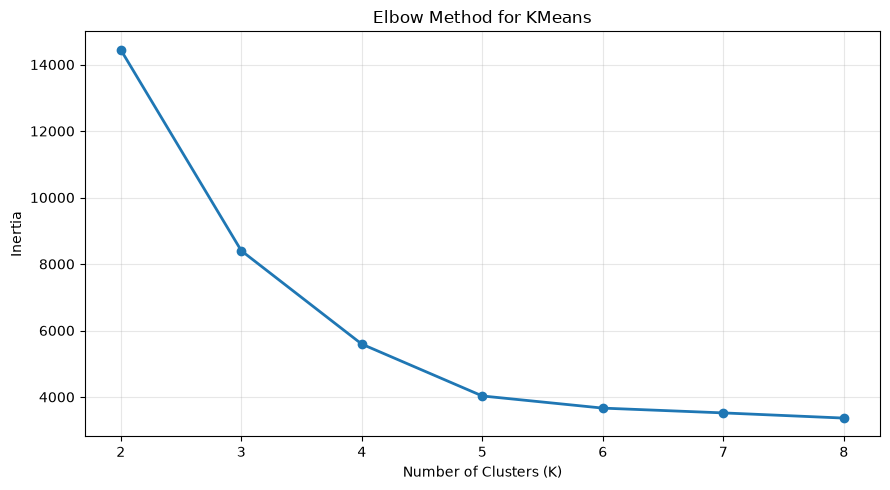

In [914]:

# Elbow Method

plt.figure(figsize=(9, 5))

plt.plot(
    kmeans_results["K"],
    kmeans_results["Inertia"],
    marker="o",
    linewidth=2
)

plt.title("Elbow Method for KMeans")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


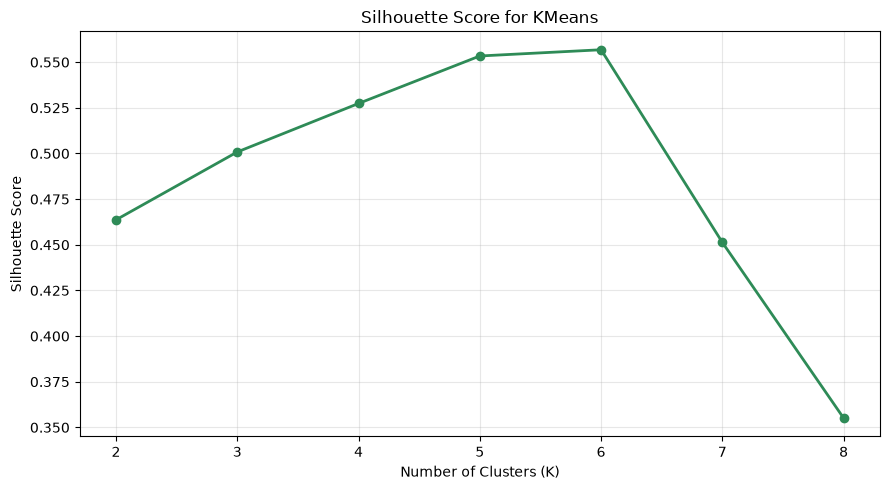

In [915]:

# Silhouette Score Comparison

plt.figure(figsize=(9, 5))

plt.plot(
    kmeans_results["K"],
    kmeans_results["Silhouette_Score"],
    marker="o",
    linewidth=2,
    color="seagreen"
)

plt.title("Silhouette Score for KMeans")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [916]:

# Find best K based on Silhouette Score

best_index = kmeans_results[
    "Silhouette_Score"
].idxmax()

best_k_silhouette = int(
    kmeans_results.loc[best_index, "K"]
)

best_silhouette_score = kmeans_results.loc[
    best_index, "Silhouette_Score"
]

print("Best K based on Silhouette:", best_k_silhouette)

print(
    "Best Silhouette Score:",
    round(best_silhouette_score, 4)
)


Best K based on Silhouette: 6
Best Silhouette Score: 0.5568


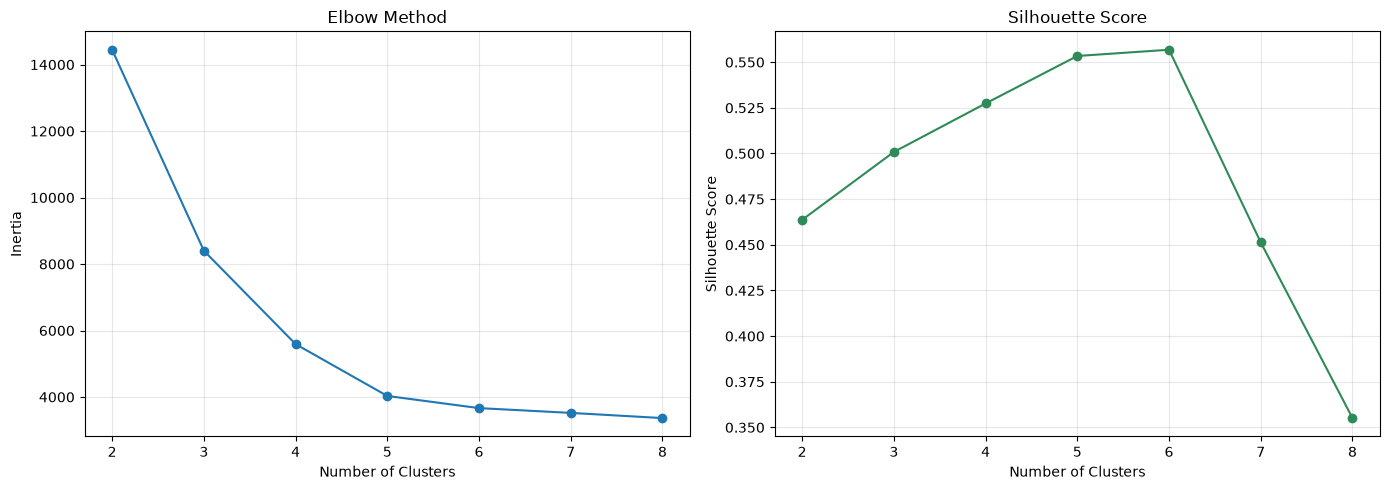

In [917]:

# Elbow and Silhouette comparison

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    kmeans_results["K"],
    kmeans_results["Inertia"],
    marker="o"
)

axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))
axes[0].grid(alpha=0.3)

axes[1].plot(
    kmeans_results["K"],
    kmeans_results["Silhouette_Score"],
    marker="o",
    color="seagreen"
)

axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Part 5.2 — KMeans Clustering Analysis

KMeans clustering was applied to the standardized customer usage dataset.

The number of clusters was evaluated from K=2 to K=8 using two methods:

**1. Elbow Method:** Inertia was calculated for each value of K to identify where adding further clusters produced diminishing improvements in within-cluster compactness.

**2. Silhouette Score:** The average silhouette coefficient was calculated to assess how well customers fit within their assigned clusters compared with neighboring clusters.

A fixed random state of 42 and 10 initializations were used for reproducibility.

**Best K by Silhouette Score:** [RESULT]

**Elbow Interpretation:** [RESULT]

**Final Selected K:** [To be determined after reviewing both methods]

The final number of clusters will be selected by considering both statistical measures and the interpretability of customer segments.

In [918]:

# Train KMeans with K=5

final_k = 5

kmeans_final = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_final.fit_predict(
    X_cluster_scaled
)

print("KMeans training completed!")
print("Selected K:", final_k)

print(
    "Final Silhouette Score:",
    round(
        silhouette_score(
            X_cluster_scaled,
            kmeans_labels
        ),
        4
    )
)


KMeans training completed!
Selected K: 5
Final Silhouette Score: 0.5534


In [919]:

# Add cluster labels to original usage data

usage_segmented = usage_clustering.copy()

usage_segmented["Cluster"] = kmeans_labels

print("Segmented Dataset Shape:")
print(usage_segmented.shape)

display(usage_segmented.head())


Segmented Dataset Shape:
(2000, 14)


,customer_id,avg_daily_data_mb,night_usage_pct,streaming_hours_week,social_media_hours_week,gaming_hours_week,calls_per_day,avg_call_minutes,intl_calls_month,roaming_days_year,topups_per_month,app_count,video_call_hours_week,Cluster
0,C00001,2433.6,36.0,14.0,6.7,9.7,2.9,1.7,2,0,3,34,2.1,0
1,C00002,1124.7,12.6,2.4,1.0,0.0,0.0,1.3,0,0,4,10,1.7,1
2,C00003,3872.5,39.6,14.0,8.6,6.7,1.9,2.7,0,11,2,37,2.1,0
3,C00004,2998.3,37.0,13.9,9.4,8.9,3.8,2.4,0,4,3,43,3.2,0
4,C00005,2816.5,36.6,12.4,10.1,10.0,2.1,2.7,2,0,2,47,2.9,0


In [920]:

# Count customers per cluster

cluster_counts = (
    usage_segmented["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_summary = pd.DataFrame({
    "Cluster": cluster_counts.index,
    "Customers": cluster_counts.values
})

cluster_summary["Percentage"] = (
    cluster_summary["Customers"]
    / len(usage_segmented)
    * 100
)

display(cluster_summary.round(2))

print(
    "Total Customers:",
    cluster_summary["Customers"].sum()
)


,Cluster,Customers,Percentage
0,0,525,26.25
1,1,454,22.70
2,2,565,28.25
3,3,418,20.90
4,4,38,1.90


Total Customers: 2000


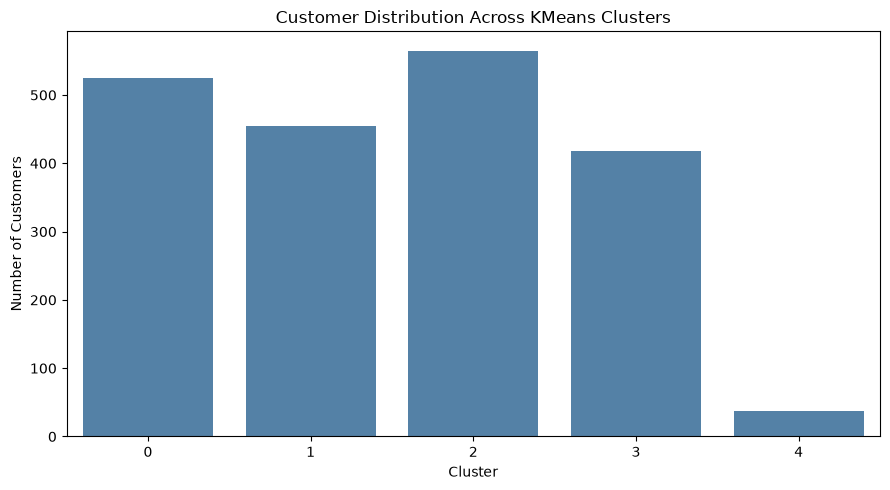

In [921]:

# Visualize cluster sizes

plt.figure(figsize=(9, 5))

sns.barplot(
    data=cluster_summary,
    x="Cluster",
    y="Customers",
    color="steelblue"
)

plt.title("Customer Distribution Across KMeans Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


In [922]:

# Compare cluster sizes at K=5 and K=6

for k in [5, 6]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(
        X_cluster_scaled
    )

    print(f"\nK = {k}")
    print(
        pd.Series(labels)
        .value_counts()
        .sort_index()
        .to_string()
    )

    print(
        "Silhouette:",
        round(
            silhouette_score(
                X_cluster_scaled,
                labels
            ),
            4
        )
    )



K = 5
0    525
1    454
2    565
3    418
4     38
Silhouette: 0.5534

K = 6
0    565
1    418
2    523
3    454
4     20
5     20
Silhouette: 0.5568


### Part 5.2 — KMeans Evaluation Results

KMeans was evaluated for cluster counts ranging from K=2 to K=8.

The Elbow Method suggested that improvements in inertia became substantially smaller after approximately K=5.

The highest Silhouette Score was achieved at K=6 (0.5568), while K=5 achieved a very similar score of 0.5534.

The difference between these scores was only 0.0034.

K=5 was therefore selected as a preliminary solution because it provides fewer, potentially more interpretable customer segments while maintaining a similar Silhouette Score.

Cluster sizes will be examined to validate this choice before proceeding with further clustering analysis.

In [923]:

# Compare cluster sizes for K=5 and K=6

for k in [5, 6]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_cluster_scaled)

    counts = pd.Series(labels).value_counts().sort_index()

    print(f"\n===== K = {k} =====")

    comparison = pd.DataFrame({
        "Cluster": counts.index,
        "Customers": counts.values,
        "Percentage": counts.values / len(labels) * 100
    })

    display(comparison.round(2))



===== K = 5 =====


,Cluster,Customers,Percentage
0,0,525,26.25
1,1,454,22.70
2,2,565,28.25
3,3,418,20.90
4,4,38,1.90



===== K = 6 =====


,Cluster,Customers,Percentage
0,0,565,28.25
1,1,418,20.90
2,2,523,26.15
3,3,454,22.70
4,4,20,1.00
5,5,20,1.00


In [924]:
final_k = 5
kmeans_final
kmeans_labels
usage_segmented

,customer_id,avg_daily_data_mb,night_usage_pct,streaming_hours_week,social_media_hours_week,gaming_hours_week,calls_per_day,avg_call_minutes,intl_calls_month,roaming_days_year,topups_per_month,app_count,video_call_hours_week,Cluster
0,C00001,2433.6,36.0,14.0,6.7,9.7,2.9,1.7,2,0,3,34,2.1,0
1,C00002,1124.7,12.6,2.4,1.0,0.0,0.0,1.3,0,0,4,10,1.7,1
2,C00003,3872.5,39.6,14.0,8.6,6.7,1.9,2.7,0,11,2,37,2.1,0
3,C00004,2998.3,37.0,13.9,9.4,8.9,3.8,2.4,0,4,3,43,3.2,0
4,C00005,2816.5,36.6,12.4,10.1,10.0,2.1,2.7,2,0,2,47,2.9,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,C01996,0.0,18.3,0.0,4.3,0.0,2.2,2.1,0,0,5,5,0.5,1
1996,C01997,2531.4,33.6,13.6,8.7,7.3,2.8,2.3,0,0,3,35,3.2,0
1997,C01998,537.7,11.5,0.0,1.4,0.0,2.0,1.3,0,0,6,8,0.5,1
1998,C01999,450.3,2.5,0.0,4.9,2.6,2.1,1.0,0,0,5,11,0.0,1


### Part 5.2 — Final KMeans Selection

KMeans clustering was evaluated for K values from 2 to 8 using the Elbow Method and Silhouette Score.

The Elbow Method suggested approximately K=5, while the highest Silhouette Score occurred at K=6 (0.5568).

However, K=5 achieved a very similar Silhouette Score of 0.5534.

The K=5 solution produced four relatively large customer groups and one small group containing 38 customers.

The K=6 solution produced four large groups and two small groups containing 20 customers each.

**Final Decision: K=5**

K=5 was selected because it provides a simpler segmentation structure while maintaining nearly the same clustering quality as K=6.

The business relevance of these segments will be examined through cluster profiling.

## Part 5.3 — Hierarchical Agglomerative Clustering

Objectives:
- Apply hierarchical clustering using Ward and Complete linkage.
- Visualize the hierarchy using a dendrogram.
- Compare clustering quality using Silhouette Score.
- Compare HAC with the selected KMeans solution.

In [925]:

# Part 5.3 - Hierarchical Clustering

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import pandas as pd

hac_results = []
hac_labels_dict = {}

for linkage_method in ["ward", "complete"]:

    hac_model = AgglomerativeClustering(
        n_clusters=5,
        linkage=linkage_method
    )

    labels = hac_model.fit_predict(
        X_cluster_scaled
    )

    score = silhouette_score(
        X_cluster_scaled,
        labels
    )

    hac_labels_dict[linkage_method] = labels

    hac_results.append({
        "Linkage": linkage_method,
        "K": 5,
        "Silhouette_Score": score
    })

hac_results_df = pd.DataFrame(hac_results)

display(hac_results_df.round(4))


,Linkage,K,Silhouette_Score
0,ward,5,0.5536
1,complete,5,0.3511


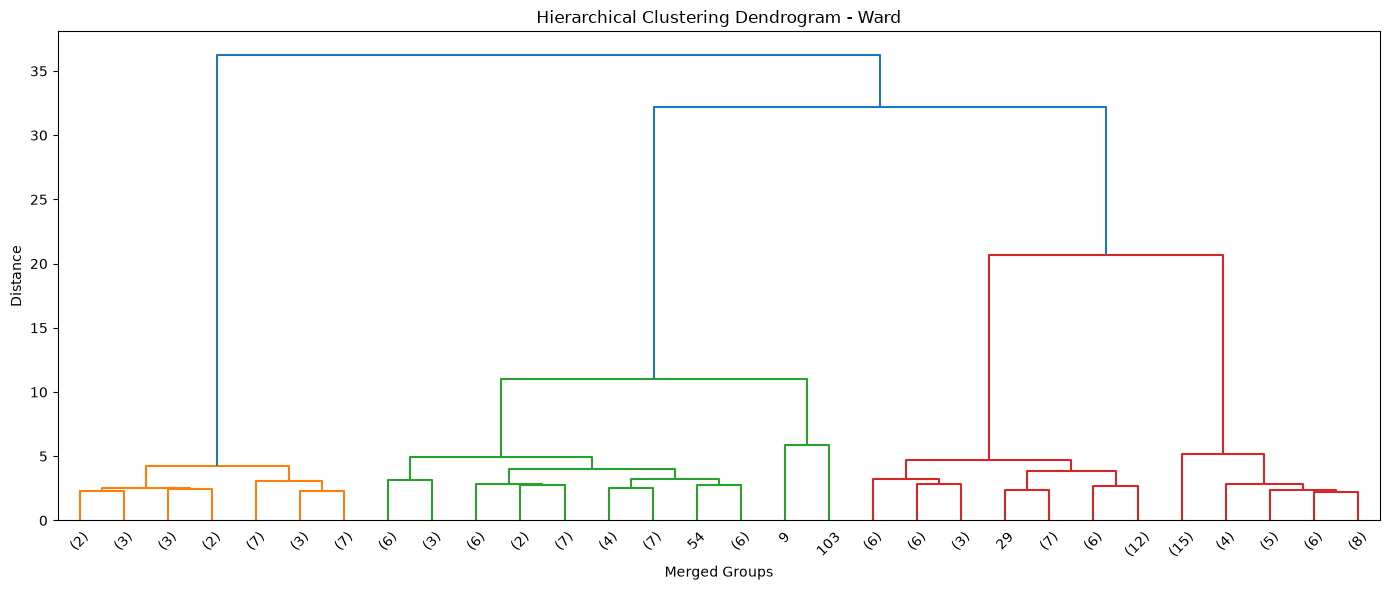

In [926]:

# Plot dendrogram using a sample of customers

from scipy.cluster.hierarchy import linkage, dendrogram
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

sample_indices = rng.choice(
    X_cluster_scaled.shape[0],
    size=min(150, X_cluster_scaled.shape[0]),
    replace=False
)

X_hac_sample = X_cluster_scaled[sample_indices]

# Ward linkage hierarchy
linkage_matrix = linkage(
    X_hac_sample,
    method="ward"
)

plt.figure(figsize=(14, 6))

dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.title("Hierarchical Clustering Dendrogram - Ward")
plt.xlabel("Merged Groups")
plt.ylabel("Distance")

plt.tight_layout()
plt.show()


In [927]:

# Compare KMeans and HAC

kmeans_score = silhouette_score(
    X_cluster_scaled,
    kmeans_labels
)

comparison_clustering = pd.concat([
    pd.DataFrame({
        "Method": ["KMeans"],
        "Silhouette_Score": [kmeans_score]
    }),
    hac_results_df.rename(
        columns={"Linkage": "Method"}
    )[["Method", "Silhouette_Score"]]
], ignore_index=True)

display(
    comparison_clustering.sort_values(
        "Silhouette_Score",
        ascending=False
    ).round(4)
)


,Method,Silhouette_Score
1,ward,0.5536
0,KMeans,0.5534
2,complete,0.3511


### Part 5.3 — Hierarchical Clustering Results

Hierarchical Agglomerative Clustering was evaluated using Ward and Complete linkage with five clusters.

**Results:**

- Ward Linkage: Silhouette Score = 0.5536
- Complete Linkage: Silhouette Score = 0.3511
- KMeans (K=5): Silhouette Score = 0.5534

Ward linkage achieved substantially better clustering quality than Complete linkage.

Ward and KMeans produced nearly identical Silhouette Scores, with a difference of only 0.0002.

KMeans was retained as the primary segmentation method because it supports direct assignment of new customers to existing clusters and offers a practical approach for operational use.

Ward linkage remains a strong alternative, while Complete linkage performed less effectively on this dataset.

## Part 5.4 — DBSCAN Clustering

Objectives:
- Use a k-distance plot to investigate suitable eps values.
- Apply DBSCAN to the standardized usage dataset.
- Identify clusters and noise points.
- Compare clustering results with KMeans and HAC.

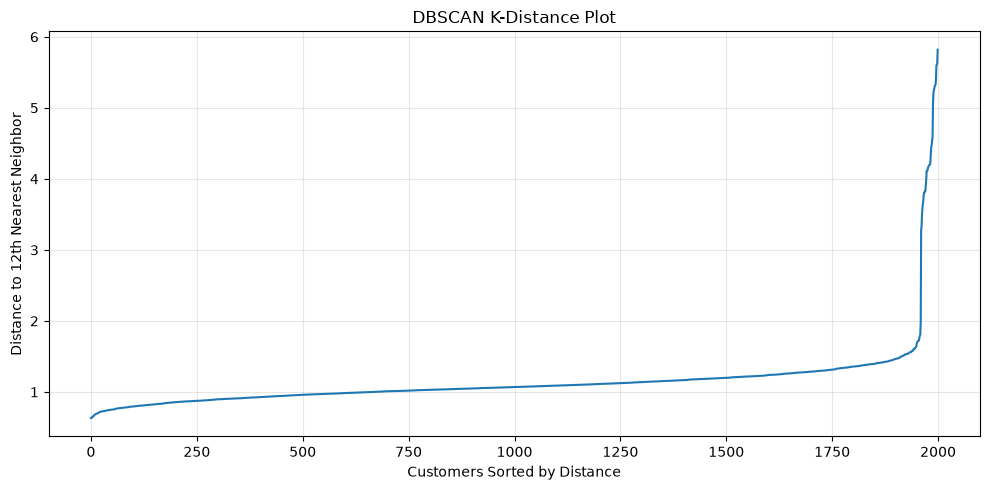

In [928]:

# Part 5.4 - DBSCAN K-Distance Plot

from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

min_samples = 12

neighbors = NearestNeighbors(
    n_neighbors=min_samples
)

neighbors.fit(X_cluster_scaled)

distances, indices = neighbors.kneighbors(
    X_cluster_scaled
)

# Distance to the 12th nearest neighbor
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))

plt.plot(k_distances)

plt.title("DBSCAN K-Distance Plot")
plt.xlabel("Customers Sorted by Distance")
plt.ylabel("Distance to 12th Nearest Neighbor")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [929]:

# DBSCAN Parameter Exploration

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import pandas as pd

eps_values = [
    1.0, 1.5, 2.0, 2.5,
    3.0, 3.5, 4.0, 4.5,
    5.0, 6.0
]

dbscan_results = []

for eps in eps_values:

    dbscan = DBSCAN(
        eps=eps,
        min_samples=12
    )

    labels = dbscan.fit_predict(
        X_cluster_scaled
    )

    # -1 represents noise
    number_of_clusters = len(
        set(labels) - {-1}
    )

    noise_count = np.sum(labels == -1)

    noise_percentage = (
        noise_count / len(labels) * 100
    )

    # Evaluate non-noise points only
    valid_mask = labels != -1

    if (
        number_of_clusters >= 2
        and valid_mask.sum() > number_of_clusters
    ):
        score = silhouette_score(
            X_cluster_scaled[valid_mask],
            labels[valid_mask]
        )
    else:
        score = np.nan

    dbscan_results.append({
        "EPS": eps,
        "Clusters": number_of_clusters,
        "Noise_Count": noise_count,
        "Noise_Percentage": noise_percentage,
        "Silhouette_Score": score
    })

dbscan_results_df = pd.DataFrame(
    dbscan_results
)

display(dbscan_results_df.round(4))


,EPS,Clusters,Noise_Count,Noise_Percentage,Silhouette_Score
0,1.0,4,573,28.65,0.5942
1,1.5,4,41,2.05,0.5607
2,2.0,2,40,2.00,0.4810
3,2.5,2,40,2.00,0.4810
4,3.0,2,40,2.00,0.4810
5,3.5,2,26,1.30,0.4085
6,4.0,3,7,0.35,0.4115
7,4.5,1,6,0.30,NaN
8,5.0,1,4,0.20,NaN
9,6.0,1,0,0.00,NaN


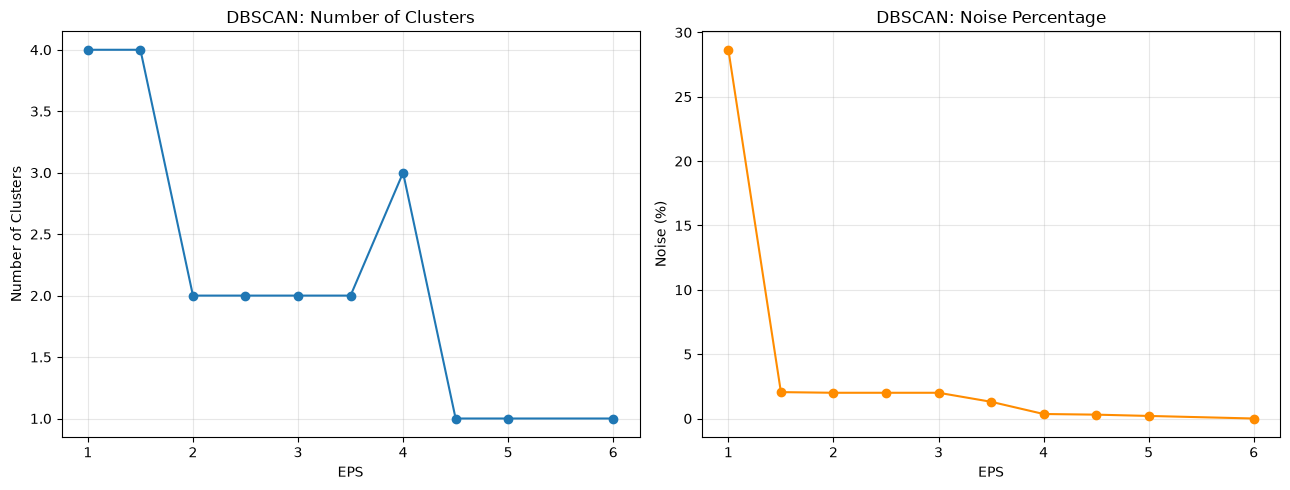

In [930]:

# Visualize DBSCAN parameter results

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    dbscan_results_df["EPS"],
    dbscan_results_df["Clusters"],
    marker="o"
)

axes[0].set_title("DBSCAN: Number of Clusters")
axes[0].set_xlabel("EPS")
axes[0].set_ylabel("Number of Clusters")
axes[0].grid(alpha=0.3)

axes[1].plot(
    dbscan_results_df["EPS"],
    dbscan_results_df["Noise_Percentage"],
    marker="o",
    color="darkorange"
)

axes[1].set_title("DBSCAN: Noise Percentage")
axes[1].set_xlabel("EPS")
axes[1].set_ylabel("Noise (%)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [931]:

# Final DBSCAN Model

from sklearn.cluster import DBSCAN
import numpy as np
import pandas as pd

dbscan_final = DBSCAN(
    eps=1.5,
    min_samples=12
)

dbscan_labels = dbscan_final.fit_predict(
    X_cluster_scaled
)

# Count clusters and noise
dbscan_cluster_count = len(
    set(dbscan_labels) - {-1}
)

dbscan_noise_count = np.sum(
    dbscan_labels == -1
)

print("Final DBSCAN Results")
print("Clusters:", dbscan_cluster_count)
print("Noise Customers:", dbscan_noise_count)
print(
    "Noise Percentage:",
    round(
        dbscan_noise_count / len(dbscan_labels) * 100,
        2
    )
)


Final DBSCAN Results
Clusters: 4
Noise Customers: 41
Noise Percentage: 2.05


In [932]:

# DBSCAN Cluster Distribution

dbscan_distribution = pd.Series(
    dbscan_labels,
    name="Cluster"
).value_counts().sort_index()

dbscan_summary = pd.DataFrame({
    "Cluster": dbscan_distribution.index,
    "Customers": dbscan_distribution.values
})

dbscan_summary["Percentage"] = (
    dbscan_summary["Customers"]
    / len(dbscan_labels) * 100
)

display(dbscan_summary.round(2))


,Cluster,Customers,Percentage
0,-1,41,2.05
1,0,522,26.10
2,1,454,22.70
3,2,418,20.90
4,3,565,28.25


### Part 5.4 — DBSCAN Results

DBSCAN was evaluated using different `eps` values with `min_samples=12` on standardized customer usage data.

The highest Silhouette Score (0.5942) occurred at `eps=1.0`, but this configuration classified 573 customers (28.65%) as noise.

A more balanced configuration was identified at `eps=1.5`, producing:

- 4 clusters
- 41 noise points (2.05%)
- Silhouette Score: 0.5607

The `eps=1.5` configuration was selected because it provided relatively strong cluster separation while retaining most customers in identified groups.

The Silhouette Score for DBSCAN was calculated on non-noise customers only, so it is not directly comparable to scores from KMeans and HAC evaluated on the full dataset.

**Conclusion:** DBSCAN offers a useful alternative for detecting dense customer groups and identifying unusual usage patterns.

## Part 5.5 — Principal Component Analysis (PCA)

Objectives:
- Apply PCA to standardized customer usage data.
- Retain approximately 90% of the total variance.
- Analyze explained variance.
- Apply KMeans on PCA-transformed data.
- Compare clustering quality before and after PCA.

In [933]:

# Part 5.5 - PCA

from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Keep at least 90% of the variance
pca_model = PCA(
    n_components=0.90,
    svd_solver="full"
)

X_cluster_pca = pca_model.fit_transform(
    X_cluster_scaled
)

print("Original Features:", X_cluster_scaled.shape[1])
print("PCA Components:", X_cluster_pca.shape[1])

print(
    "Total Explained Variance:",
    round(
        pca_model.explained_variance_ratio_.sum(),
        4
    )
)


Original Features: 12
PCA Components: 5
Total Explained Variance: 0.9242


In [934]:

# Explained Variance Table

explained_variance = (
    pca_model.explained_variance_ratio_
)

cumulative_variance = np.cumsum(
    explained_variance
)

pca_results_df = pd.DataFrame({
    "Component": np.arange(
        1,
        len(explained_variance) + 1
    ),
    "Explained_Variance": explained_variance,
    "Cumulative_Variance": cumulative_variance
})

display(pca_results_df.round(4))


,Component,Explained_Variance,Cumulative_Variance
0,1,0.4359,0.4359
1,2,0.2964,0.7323
2,3,0.0812,0.8135
3,4,0.0793,0.8928
4,5,0.0314,0.9242


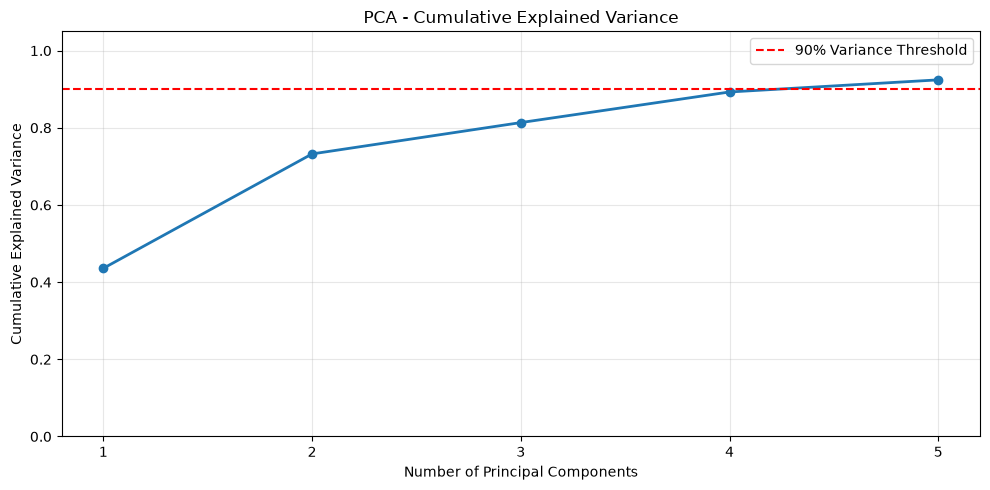

In [935]:

# Plot PCA Explained Variance

plt.figure(figsize=(10, 5))

plt.plot(
    pca_results_df["Component"],
    pca_results_df["Cumulative_Variance"],
    marker="o",
    linewidth=2
)

plt.axhline(
    y=0.90,
    color="red",
    linestyle="--",
    label="90% Variance Threshold"
)

plt.title("PCA - Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")

plt.xticks(pca_results_df["Component"])
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


In [936]:

# KMeans after PCA

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans_pca = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

pca_cluster_labels = kmeans_pca.fit_predict(
    X_cluster_pca
)

silhouette_pca = silhouette_score(
    X_cluster_pca,
    pca_cluster_labels
)

silhouette_original = silhouette_score(
    X_cluster_scaled,
    kmeans_labels
)

print(
    "Original KMeans Silhouette:",
    round(silhouette_original, 4)
)

print(
    "PCA KMeans Silhouette:",
    round(silhouette_pca, 4)
)


Original KMeans Silhouette: 0.5534
PCA KMeans Silhouette: 0.6668


In [937]:

# PCA vs Original KMeans Comparison

pca_comparison = pd.DataFrame({
    "Method": [
        "KMeans - Original Features",
        "KMeans - PCA Features"
    ],
    "Features": [
        X_cluster_scaled.shape[1],
        X_cluster_pca.shape[1]
    ],
    "Silhouette_Score": [
        silhouette_original,
        silhouette_pca
    ]
})

display(pca_comparison.round(4))


,Method,Features,Silhouette_Score
0,KMeans - Original Features,12,0.5534
1,KMeans - PCA Features,5,0.6668


In [938]:

# Compare both KMeans labelings in the original feature space

from sklearn.metrics import silhouette_score
import pandas as pd

original_labels_original_space = silhouette_score(
    X_cluster_scaled,
    kmeans_labels
)

pca_labels_original_space = silhouette_score(
    X_cluster_scaled,
    pca_cluster_labels
)

fair_comparison = pd.DataFrame({
    "Clustering_Method": [
        "KMeans on Original Features",
        "KMeans after PCA"
    ],
    "Silhouette_on_Original_Space": [
        original_labels_original_space,
        pca_labels_original_space
    ]
})

display(fair_comparison.round(4))


,Clustering_Method,Silhouette_on_Original_Space
0,KMeans on Original Features,0.5534
1,KMeans after PCA,0.5534


## Part 5.6 — Customer Segment Profiling

Objectives:
- Profile the five customer clusters.
- Compare average usage behavior across segments.
- Identify distinguishing features.
- Assign meaningful business names.
- Recommend suitable offers for each customer segment.

In [939]:

# Part 5.6 - Customer Segment Profiles

import pandas as pd

# Original KMeans labels (K=5)
segment_profiles = usage_segmented.groupby(
    "Cluster"
)[X_cluster.columns.tolist()].mean()

# Number of customers per cluster
segment_profiles.insert(
    0,
    "Customers",
    usage_segmented.groupby("Cluster").size()
)

display(segment_profiles.round(2))


,Customers,avg_daily_data_mb,night_usage_pct,streaming_hours_week,social_media_hours_week,gaming_hours_week,calls_per_day,avg_call_minutes,intl_calls_month,roaming_days_year,topups_per_month,app_count,video_call_hours_week
Cluster,,,,,,,,,,,,,
0,525,2831.45,37.86,14.10,9.89,8.01,2.94,1.97,1.03,3.22,3.01,38.01,2.95
1,454,326.19,12.28,1.07,2.20,0.59,2.90,1.50,0.45,1.32,5.00,7.90,0.45
2,565,1097.71,22.19,2.95,13.96,1.31,6.04,2.47,1.13,2.37,4.00,29.85,2.00
3,418,621.98,9.43,1.37,3.04,0.63,14.08,4.50,9.13,21.72,2.02,14.02,5.00
4,38,7488.59,82.05,2.72,7.53,1.51,24.08,2.52,2.29,5.61,4.18,19.03,2.19


In [940]:

# Compare cluster means using standardized features

scaled_profiles_df = pd.DataFrame(
    X_cluster_scaled,
    columns=X_cluster.columns
)

scaled_profiles_df["Cluster"] = kmeans_labels

cluster_z_profiles = (
    scaled_profiles_df
    .groupby("Cluster")
    .mean()
)

display(cluster_z_profiles.round(2))


,avg_daily_data_mb,night_usage_pct,streaming_hours_week,social_media_hours_week,gaming_hours_week,calls_per_day,avg_call_minutes,intl_calls_month,roaming_days_year,topups_per_month,app_count,video_call_hours_week
Cluster,,,,,,,,,,,,
0,1.05,1.04,1.58,0.39,1.54,-0.64,-0.49,-0.46,-0.38,-0.38,1.15,0.25
1,-0.79,-0.70,-0.71,-1.05,-0.64,-0.65,-0.88,-0.62,-0.61,1.01,-1.24,-1.22
2,-0.22,-0.02,-0.38,1.15,-0.43,-0.09,-0.07,-0.43,-0.49,0.31,0.50,-0.31
3,-0.57,-0.89,-0.66,-0.90,-0.63,1.34,1.66,1.84,1.81,-1.08,-0.75,1.46
4,4.48,4.05,-0.42,-0.05,-0.37,3.13,-0.02,-0.10,-0.10,0.44,-0.35,-0.20


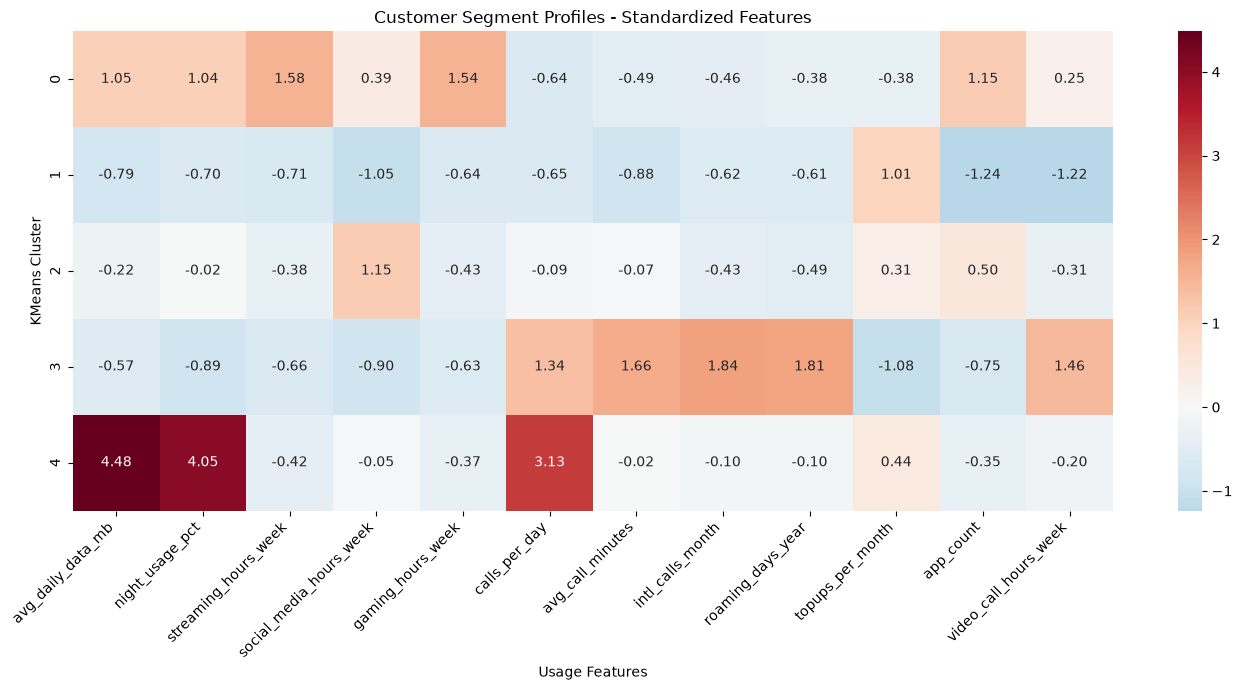

In [941]:

# Cluster behavior heatmap

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))

sns.heatmap(
    cluster_z_profiles,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0
)

plt.title("Customer Segment Profiles - Standardized Features")
plt.xlabel("Usage Features")
plt.ylabel("KMeans Cluster")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [942]:

# Identify the strongest distinguishing features

for cluster_id in cluster_z_profiles.index:

    profile = cluster_z_profiles.loc[cluster_id]

    strongest_features = (
        profile.abs()
        .sort_values(ascending=False)
        .head(4)
        .index
    )

    print(f"\nCluster {cluster_id} - Main Characteristics:")

    for feature in strongest_features:
        value = profile[feature]

        direction = (
            "Above Average"
            if value > 0
            else "Below Average"
        )

        print(
            f"  {feature}: "
            f"{value:+.2f} ({direction})"
        )



Cluster 0 - Main Characteristics:
  streaming_hours_week: +1.58 (Above Average)
  gaming_hours_week: +1.54 (Above Average)
  app_count: +1.15 (Above Average)
  avg_daily_data_mb: +1.05 (Above Average)

Cluster 1 - Main Characteristics:
  app_count: -1.24 (Below Average)
  video_call_hours_week: -1.22 (Below Average)
  social_media_hours_week: -1.05 (Below Average)
  topups_per_month: +1.01 (Above Average)

Cluster 2 - Main Characteristics:
  social_media_hours_week: +1.15 (Above Average)
  app_count: +0.50 (Above Average)
  roaming_days_year: -0.49 (Below Average)
  intl_calls_month: -0.43 (Below Average)

Cluster 3 - Main Characteristics:
  intl_calls_month: +1.84 (Above Average)
  roaming_days_year: +1.81 (Above Average)
  avg_call_minutes: +1.66 (Above Average)
  video_call_hours_week: +1.46 (Above Average)

Cluster 4 - Main Characteristics:
  avg_daily_data_mb: +4.48 (Above Average)
  night_usage_pct: +4.05 (Above Average)
  calls_per_day: +3.13 (Above Average)
  topups_per_month:

### Part 5.5 — PCA Results and Interpretation

Principal Component Analysis (PCA) was applied to the standardized customer usage data to reduce dimensionality while preserving at least 90% of total variance.

The original dataset contained 12 behavioral features.

PCA reduced these to **5 principal components**, retaining **92.42%** of the total variance.

The first two components explained 73.23% of the variance, while the first four explained 89.28%. A fifth component was required to exceed the 90% threshold.

KMeans with K=5 achieved a Silhouette Score of 0.5534 on the original standardized features and 0.6668 in the PCA-transformed space.

The higher PCA-space score indicates stronger separation under the reduced-space distance metric, but the two values are not directly comparable because the feature spaces differ.

A common-space silhouette comparison was also performed to evaluate the cluster assignments more consistently.

**Conclusion:** PCA reduced dimensionality substantially while preserving most of the dataset's variance, making it useful for efficient clustering and visualization.

In [943]:

# Assign business-friendly segment names

segment_names = {
    0: "Digital Entertainment Users",
    1: "Light Usage Customers",
    2: "Social Media Users",
    3: "International & Voice Users",
    4: "Extreme Night & Data Users"
}

# Add descriptive labels
usage_segmented["Segment_Name"] = (
    usage_segmented["Cluster"].map(segment_names)
)

# Segment summary
segment_business_summary = (
    usage_segmented
    .groupby(["Cluster", "Segment_Name"])
    .size()
    .reset_index(name="Customers")
)

segment_business_summary["Percentage"] = (
    segment_business_summary["Customers"]
    / len(usage_segmented) * 100
)

display(segment_business_summary.round(2))


,Cluster,Segment_Name,Customers,Percentage
0,0,Digital Entertainment Users,525,26.25
1,1,Light Usage Customers,454,22.70
2,2,Social Media Users,565,28.25
3,3,International & Voice Users,418,20.90
4,4,Extreme Night & Data Users,38,1.90


In [944]:

# Recommended offers for each segment

segment_offers = {
    0: "High-data streaming and gaming bundle",
    1: "Affordable basic mobile plan",
    2: "Social media data bundle",
    3: "International calls and roaming package",
    4: "High-volume data and night usage package"
}

segment_business_summary["Recommended_Offer"] = (
    segment_business_summary["Cluster"].map(
        segment_offers
    )
)

display(segment_business_summary)


,Cluster,Segment_Name,Customers,Percentage,Recommended_Offer
0,0,Digital Entertainment Users,525,26.25,High-data streaming and gaming bundle
1,1,Light Usage Customers,454,22.70,Affordable basic mobile plan
2,2,Social Media Users,565,28.25,Social media data bundle
3,3,International & Voice Users,418,20.90,International calls and roaming package
4,4,Extreme Night & Data Users,38,1.90,High-volume data and night usage package


### Part 5.6 — Customer Segmentation and Business Recommendations

KMeans clustering with K=5 identified five customer segments based on 12 usage behavior features.

**Cluster 0 — Digital Entertainment Users (26.25%)**

These customers demonstrate relatively high daily data consumption, streaming activity, and gaming usage. Large data bundles designed for digital entertainment are recommended.

**Cluster 1 — Light Usage Customers (22.70%)**

These customers have comparatively low internet consumption, streaming activity, and gaming usage. Affordable mobile plans with basic data allowances may better match their needs.

**Cluster 2 — Social Media Users (28.25%)**

These customers are distinguished by relatively high social media usage. Social media-oriented data packages are recommended.

**Cluster 3 — International & Voice Users (20.90%)**

These customers demonstrate high calling activity, international calls, and roaming usage. International calling bundles and roaming packages are recommended.

**Cluster 4 — Extreme Night & Data Users (1.90%)**

This small customer segment demonstrates exceptionally high daily data consumption and a large proportion of nighttime usage. Specialized high-volume and nighttime data packages could be investigated.

### Overall Business Recommendation

Nile Connect should consider differentiated service bundles rather than offering the same packages to all customers.

Behavioral segmentation can support targeted marketing, product personalization, and customer retention strategies.

These recommendations are hypotheses based on observed usage patterns. Their commercial effectiveness should be validated through customer research and controlled experiments.

In [945]:

# Fair comparison: KMeans before and after PCA

from sklearn.metrics import silhouette_score
import pandas as pd

fair_comparison = pd.DataFrame({
    "Method": [
        "Original KMeans",
        "PCA KMeans"
    ],
    "Silhouette_on_Original_Data": [
        silhouette_score(
            X_cluster_scaled,
            kmeans_labels
        ),
        silhouette_score(
            X_cluster_scaled,
            pca_cluster_labels
        )
    ]
})

display(fair_comparison.round(4))


,Method,Silhouette_on_Original_Data
0,Original KMeans,0.5534
1,PCA KMeans,0.5534


### Part 5 — Final Conclusion

Customer segmentation was performed using KMeans, Hierarchical Agglomerative Clustering, and DBSCAN.

KMeans with K=5 was selected as the primary segmentation approach, achieving a Silhouette Score of 0.5534.

Ward linkage achieved a similar Silhouette Score of 0.5536, while Complete linkage performed less effectively.

DBSCAN identified four clusters and 41 noise points using eps=1.5 and min_samples=12.

PCA reduced the original 12 behavioral features to five principal components while preserving 92.42% of total variance.

KMeans applied to the PCA-transformed features achieved a Silhouette Score of 0.6668 in PCA space.

When both clustering solutions were evaluated in the original standardized feature space, they achieved the same rounded Silhouette Score of 0.5534.

Five customer segments were identified and assigned business-oriented names based on their usage behavior.

**Business Recommendation:** Nile Connect can use these segments to investigate personalized data, entertainment, social media, and international calling packages.

The effectiveness of these offers should be tested before deployment.

# Part 6 — Association Rule Mining

## Part 6.1 — Transaction Data Preparation

Objectives:
- Explore service transaction data.
- Identify unique services and transactions.
- Convert transactions into a one-hot encoded basket format.
- Prepare the dataset for Apriori.

In [946]:

# Part 6.1 - Explore Service Transactions

import pandas as pd
import numpy as np

# We loaded this dataset in Part 1
transactions_df = transactions.copy()

print("Dataset Shape:", transactions_df.shape)

print("\nColumn Names:")
print(transactions_df.columns.tolist())

print("\nFirst 10 Rows:")
display(transactions_df.head(10))

print("\nMissing Values:")
print(transactions_df.isnull().sum())

print("\nDuplicate Rows:")
print(transactions_df.duplicated().sum())


Dataset Shape: (12993, 2)

Column Names:
['transaction_id', 'service']

First 10 Rows:


,transaction_id,service
0,T02071,Extra_Minutes
1,T03753,Roaming_Pack
2,T02047,Cloud_Storage
3,T00394,Home_Internet
4,T02490,Extra_Minutes
5,T01012,Router_Upgrade
6,T02890,Router_Upgrade
7,T03848,Home_Internet
8,T02760,Mobile_Wallet
9,T04010,Mobile_Data_Pack



Missing Values:
transaction_id    0
service           0
dtype: int64

Duplicate Rows:
0


In [947]:

# Inspect transaction data types

print("Transaction Data Types:")
display(transactions_df.dtypes.to_frame("Data_Type"))

print("\nSample Records:")
display(transactions_df.sample(
    min(5, len(transactions_df)),
    random_state=42
))


Transaction Data Types:


,Data_Type
transaction_id,str
service,str



Sample Records:


,transaction_id,service
8568,T03099,Landline
3780,T02208,Streaming_Bundle
5924,T01944,Home_Internet
4894,T01431,Mobile_Data_Pack
10697,T02485,Device_Installment


In [948]:

# Part 6.1 - Transaction Statistics

total_rows = len(transactions_df)

unique_transactions = (
    transactions_df["transaction_id"].nunique()
)

unique_services = (
    transactions_df["service"].nunique()
)

print("Total Rows:", total_rows)
print("Unique Transactions:", unique_transactions)
print("Unique Services:", unique_services)

print("\nAvailable Services:")
print(
    sorted(
        transactions_df["service"].unique()
    )
)


Total Rows: 12993
Unique Transactions: 4500
Unique Services: 13

Available Services:
['Antivirus', 'Cloud_Storage', 'Device_Installment', 'Extra_Minutes', 'Family_Line', 'Home_Internet', 'Intl_Calling', 'Landline', 'Mobile_Data_Pack', 'Mobile_Wallet', 'Roaming_Pack', 'Router_Upgrade', 'Streaming_Bundle']


In [949]:

# Count services per transaction

services_per_transaction = (
    transactions_df
    .groupby("transaction_id")["service"]
    .nunique()
)

print("Services per Transaction Summary:")
display(services_per_transaction.describe())

print("\nSample Transactions:")
display(
    transactions_df
    .groupby("transaction_id")["service"]
    .apply(list)
    .head(10)
)


Services per Transaction Summary:


count    4500.000000
mean        2.887333
std         1.771817
min         1.000000
25%         1.000000
50%         3.000000
75%         4.000000
max        11.000000
Name: service, dtype: float64


Sample Transactions:


transaction_id
T00001    [Roaming_Pack, Mobile_Wallet, Mobile_Data_Pack...
T00002                                      [Extra_Minutes]
T00003    [Landline, Roaming_Pack, Cloud_Storage, Family...
T00004                                      [Extra_Minutes]
T00005                                   [Mobile_Data_Pack]
T00006                                      [Mobile_Wallet]
T00007    [Extra_Minutes, Router_Upgrade, Home_Internet,...
T00008                                      [Extra_Minutes]
T00009                                      [Extra_Minutes]
T00010        [Roaming_Pack, Router_Upgrade, Home_Internet]
Name: service, dtype: object

In [950]:

# Create transaction-service basket matrix

basket = pd.crosstab(
    transactions_df["transaction_id"],
    transactions_df["service"]
)

# Convert counts to boolean values
basket = basket.gt(0)

print("Basket Matrix Shape:", basket.shape)

display(basket.head())


Basket Matrix Shape: (4500, 13)


service,Antivirus,Cloud_Storage,Device_Installment,Extra_Minutes,Family_Line,Home_Internet,Intl_Calling,Landline,Mobile_Data_Pack,Mobile_Wallet,Roaming_Pack,Router_Upgrade,Streaming_Bundle
transaction_id,,,,,,,,,,,,,
T00001,False,False,False,True,False,True,True,False,True,True,True,True,True
T00002,False,False,False,True,False,False,False,False,False,False,False,False,False
T00003,False,True,False,False,True,True,True,True,True,False,True,False,False
T00004,False,False,False,True,False,False,False,False,False,False,False,False,False
T00005,False,False,False,False,False,False,False,False,True,False,False,False,False


In [951]:

# Validate the basket matrix

print("Number of Transactions:", basket.shape[0])
print("Number of Services:", basket.shape[1])

print("\nMissing Values:", basket.isnull().sum().sum())

print("\nBasket Data Types:")
print(basket.dtypes.value_counts())

print("\nTotal Service Occurrences:")
print(basket.sum().sum())

# Verify service occurrences match distinct pairs
unique_pairs = transactions_df[
    ["transaction_id", "service"]
].drop_duplicates().shape[0]

assert basket.sum().sum() == unique_pairs
assert basket.shape[0] == unique_transactions
assert basket.shape[1] == unique_services

print("\nBasket validation passed!")


Number of Transactions: 4500
Number of Services: 13

Missing Values: 0

Basket Data Types:
bool    13
Name: count, dtype: int64

Total Service Occurrences:
12993

Basket validation passed!


In [952]:
%pip install mlxtend

Note: you may need to restart the kernel to use updated packages.


In [953]:

# Part 6.2 - Apriori Frequent Itemsets

from mlxtend.frequent_patterns import apriori

frequent_itemsets = apriori(
    basket,
    min_support=0.03,
    use_colnames=True
)

frequent_itemsets["Length"] = (
    frequent_itemsets["itemsets"].apply(len)
)

frequent_itemsets = frequent_itemsets.sort_values(
    "support",
    ascending=False
).reset_index(drop=True)

print("Number of Frequent Itemsets:", len(frequent_itemsets))

display(frequent_itemsets.head(15))


Number of Frequent Itemsets: 109


,support,itemsets,Length
0,0.519556,frozenset({Mobile_Data_Pack}),1
1,0.386444,frozenset({Home_Internet}),1
2,0.323556,frozenset({Router_Upgrade}),1
3,0.323556,frozenset({Extra_Minutes}),1
4,0.301111,"frozenset({Home_Internet, Router_Upgrade})",2
5,0.269333,frozenset({Streaming_Bundle}),1
6,0.224889,frozenset({Mobile_Wallet}),1
7,0.194667,"frozenset({Home_Internet, Streaming_Bundle})",2
8,0.178222,"frozenset({Home_Internet, Mobile_Data_Pack})",2
9,0.166222,frozenset({Cloud_Storage}),1


In [954]:

# Count itemsets by number of services

itemset_summary = (
    frequent_itemsets["Length"]
    .value_counts()
    .sort_index()
    .reset_index()
)

itemset_summary.columns = [
    "Number_of_Services",
    "Frequent_Itemsets"
]

display(itemset_summary)


,Number_of_Services,Frequent_Itemsets
0,1,13
1,2,46
2,3,40
3,4,10


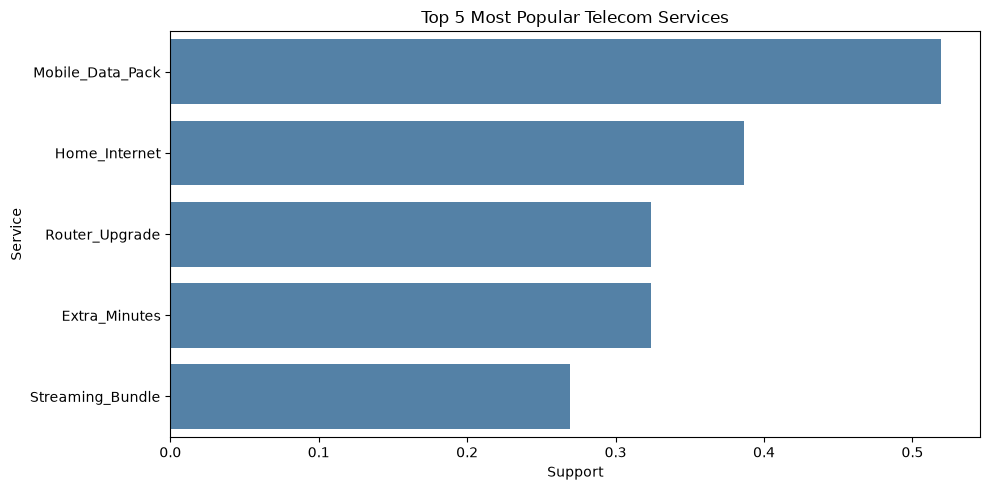

In [955]:

# Part 6.2 - Top 5 Most Popular Services

import matplotlib.pyplot as plt
import seaborn as sns

# Select individual services only
single_services = frequent_itemsets[
    frequent_itemsets["Length"] == 1
].copy()

# Convert itemsets to service names
single_services["Service"] = (
    single_services["itemsets"]
    .apply(lambda x: next(iter(x)))
)

# Select top 5 by support
top_5_services = (
    single_services
    .sort_values("support", ascending=False)
    .head(5)
)

# Plot
plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_5_services,
    x="support",
    y="Service",
    color="steelblue"
)

plt.title("Top 5 Most Popular Telecom Services")
plt.xlabel("Support")
plt.ylabel("Service")

plt.tight_layout()
plt.show()


### Business Insight

Mobile Data Pack is the most popular service,
appearing in approximately 51.96% of transactions.

Home Internet and Router Upgrade are also widely used,
suggesting opportunities for home connectivity bundles.

### Part 6.1–6.2 — Transaction Preparation and Apriori

The service transaction dataset contains 12,993 rows with two columns: `transaction_id` and `service`.

Each row represents a service associated with a transaction.

The dataset was converted into a transaction-service basket matrix, where each transaction is represented by a row and each available service by a Boolean column.

The Apriori algorithm was then applied with a minimum support threshold of 0.03 to identify frequent individual services and service combinations.

The resulting frequent itemsets will be used to generate association rules and evaluate their support, confidence, and lift.

## Part 6.3 — Association Rule Generation

Objectives:
- Generate association rules from frequent itemsets.
- Evaluate Support, Confidence, and Lift.
- Identify strong service associations.
- Find opportunities for cross-selling and bundling.

In [956]:

# Part 6.3 - Generate Association Rules

from mlxtend.frequent_patterns import association_rules

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.5,
    num_itemsets=len(basket)
)

print("Total Association Rules:", len(rules))

display(rules.head())


Total Association Rules: 112


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({Home_Internet}),frozenset({Router_Upgrade}),0.386444,0.323556,0.301111,0.779183,2.408191,1.0,0.176075,3.063377,0.953052,0.736413,0.673563,0.854908
1,frozenset({Router_Upgrade}),frozenset({Home_Internet}),0.323556,0.386444,0.301111,0.930632,2.408191,1.0,0.176075,8.844920,0.864447,0.736413,0.886941,0.854908
2,frozenset({Home_Internet}),frozenset({Streaming_Bundle}),0.386444,0.269333,0.194667,0.503738,1.870314,1.0,0.090584,1.472340,0.758416,0.422169,0.320809,0.613255
3,frozenset({Streaming_Bundle}),frozenset({Home_Internet}),0.269333,0.386444,0.194667,0.722772,1.870314,1.0,0.090584,2.213183,0.636857,0.422169,0.548162,0.613255
4,frozenset({Streaming_Bundle}),frozenset({Router_Upgrade}),0.269333,0.323556,0.160889,0.597360,1.846235,1.0,0.073745,1.680022,0.627314,0.372428,0.404770,0.547306


In [957]:

# Create readable association rules

rules_readable = rules.copy()

rules_readable["Antecedents"] = (
    rules_readable["antecedents"]
    .apply(lambda x: ", ".join(sorted(x)))
)

rules_readable["Consequents"] = (
    rules_readable["consequents"]
    .apply(lambda x: ", ".join(sorted(x)))
)

rules_summary = rules_readable[
    [
        "Antecedents",
        "Consequents",
        "support",
        "confidence",
        "lift"
    ]
].copy()

rules_summary = rules_summary.sort_values(
    ["lift", "confidence"],
    ascending=False
).reset_index(drop=True)

display(rules_summary.head(20).round(4))


,Antecedents,Consequents,support,confidence,lift
0,"Antivirus, Home_Internet","Device_Installment, Router_Upgrade",0.0307,0.5149,13.3940
1,"Device_Installment, Router_Upgrade","Antivirus, Home_Internet",0.0307,0.7977,13.3940
2,"Antivirus, Router_Upgrade","Device_Installment, Home_Internet",0.0307,0.6419,13.3721
3,"Device_Installment, Home_Internet","Antivirus, Router_Upgrade",0.0307,0.6389,13.3721
4,"Home_Internet, Roaming_Pack",Intl_Calling,0.0340,0.7766,9.1251
5,"Intl_Calling, Mobile_Data_Pack",Roaming_Pack,0.0404,0.9381,9.1180
6,"Home_Internet, Intl_Calling",Roaming_Pack,0.0340,0.9329,9.0673
7,"Mobile_Data_Pack, Roaming_Pack",Intl_Calling,0.0404,0.7712,9.0609
8,Intl_Calling,Roaming_Pack,0.0784,0.9217,8.9579
9,Roaming_Pack,Intl_Calling,0.0784,0.7624,8.9579


In [958]:

# Filter strong association rules

strong_rules = rules_summary[
    (rules_summary["confidence"] >= 0.5)
    & (rules_summary["lift"] > 1)
].copy()

strong_rules = strong_rules.sort_values(
    ["lift", "confidence"],
    ascending=False
)

print("Number of Strong Rules:", len(strong_rules))

display(strong_rules.head(15).round(4))


Number of Strong Rules: 109


,Antecedents,Consequents,support,confidence,lift
0,"Antivirus, Home_Internet","Device_Installment, Router_Upgrade",0.0307,0.5149,13.3940
1,"Device_Installment, Router_Upgrade","Antivirus, Home_Internet",0.0307,0.7977,13.3940
2,"Antivirus, Router_Upgrade","Device_Installment, Home_Internet",0.0307,0.6419,13.3721
3,"Device_Installment, Home_Internet","Antivirus, Router_Upgrade",0.0307,0.6389,13.3721
4,"Home_Internet, Roaming_Pack",Intl_Calling,0.0340,0.7766,9.1251
5,"Intl_Calling, Mobile_Data_Pack",Roaming_Pack,0.0404,0.9381,9.1180
6,"Home_Internet, Intl_Calling",Roaming_Pack,0.0340,0.9329,9.0673
7,"Mobile_Data_Pack, Roaming_Pack",Intl_Calling,0.0404,0.7712,9.0609
8,Intl_Calling,Roaming_Pack,0.0784,0.9217,8.9579
9,Roaming_Pack,Intl_Calling,0.0784,0.7624,8.9579


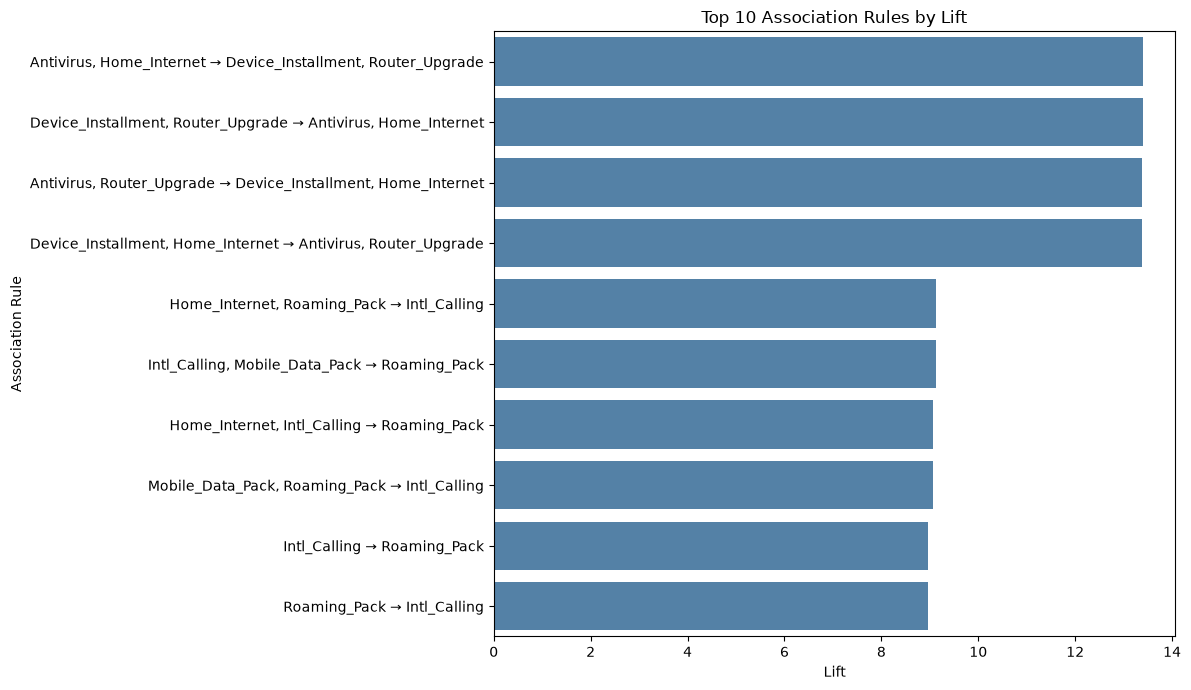

In [959]:

# Visualize top 10 association rules by Lift

import matplotlib.pyplot as plt
import seaborn as sns

top_10_rules = strong_rules.head(10).copy()

top_10_rules["Rule"] = (
    top_10_rules["Antecedents"]
    + " → "
    + top_10_rules["Consequents"]
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_rules,
    x="lift",
    y="Rule",
    color="steelblue"
)

plt.title("Top 10 Association Rules by Lift")
plt.xlabel("Lift")
plt.ylabel("Association Rule")

plt.tight_layout()
plt.show()


### Part 6.3 — Association Rule Mining

Association rules were generated from frequent itemsets using a minimum confidence threshold of 0.50.

The rules were evaluated using Support, Confidence, and Lift.

Rules with Lift greater than 1 were considered positively associated and examined as potential cross-selling opportunities.

One notable relationship was Home Internet → Router Upgrade, with approximately 77.92% confidence and a Lift of 2.41.

This suggests that Router Upgrade is substantially more common in transactions containing Home Internet than in transactions overall.

However, these relationships are observational and do not establish causation or guarantee that a bundle will increase sales.

In [960]:

# Part 6.4 - Selected Business Rules

selected_pairs = [
    ("Home_Internet", "Router_Upgrade"),
    ("Intl_Calling", "Roaming_Pack"),
    ("Device_Installment", "Antivirus")
]

selected_rules = rules_summary[
    rules_summary.apply(
        lambda row: (
            row["Antecedents"],
            row["Consequents"]
        ) in selected_pairs,
        axis=1
    )
].copy()

display(selected_rules.round(4))


,Antecedents,Consequents,support,confidence,lift
8,Intl_Calling,Roaming_Pack,0.0784,0.9217,8.9579
14,Device_Installment,Antivirus,0.0933,0.8367,5.9666
62,Home_Internet,Router_Upgrade,0.3011,0.7792,2.4082


In [961]:

# Part 6.4 - Bundle Recommendations

bundle_recommendations = pd.DataFrame({
    "Bundle_Name": [
        "Home Connectivity Bundle",
        "International Traveler Bundle",
        "Device Protection Bundle"
    ],
    "Services": [
        "Home Internet + Router Upgrade",
        "International Calling + Roaming Pack",
        "Device Installment + Antivirus"
    ],
    "Business_Goal": [
        "Increase home connectivity cross-selling",
        "Offer relevant services to travelers",
        "Combine device financing with protection"
    ]
})

display(bundle_recommendations)


,Bundle_Name,Services,Business_Goal
0,Home Connectivity Bundle,Home Internet + Router Upgrade,Increase home connectivity cross-selling
1,International Traveler Bundle,International Calling + Roaming Pack,Offer relevant services to travelers
2,Device Protection Bundle,Device Installment + Antivirus,Combine device financing with protection


### Part 6 — Final Association Rule Mining Conclusions

The Apriori algorithm was applied to a transaction-service basket matrix using a minimum support threshold of 0.03.

A total of 109 frequent itemsets were identified, including 13 single-service itemsets, 46 pairs, 40 three-service combinations, and 10 four-service combinations.

Association rules were generated using a minimum confidence threshold of 0.50, and positive associations were identified using Lift greater than 1.

**Key Findings**

1. International Calling → Roaming Pack achieved a confidence of 0.9217 and a lift of 8.9579.
2. Device Installment → Antivirus achieved a confidence of 0.8367 and a lift of 5.9666.
3. Home Internet and Router Upgrade appeared together in 30.11% of transactions.

**Recommended Service Bundles**

- Home Connectivity Bundle: Home Internet + Router Upgrade.
- International Traveler Bundle: International Calling + Roaming Pack.
- Device Protection Bundle: Device Installment + Antivirus.

These recommendations are based on observed co-occurrence patterns. Commercial testing is required to determine whether bundled offers increase sales, retention, or customer satisfaction.

**Conclusion:** Association Rule Mining identified useful relationships between telecom services that can support targeted cross-selling and bundle development.

# Part 7 — Customer Segmentation and Churn Integration

## Part 7.1 — Merge Customer and Segment Data

Objectives:
- Merge customer records with KMeans segment labels.
- Analyze churn rates across customer segments.
- Prepare data for comparing churn models with and
  without segment information.

In [962]:

# Part 7.1 - Merge customer data with segments

# Keep customer IDs and cluster labels
customer_segments = usage_segmented[
    ["customer_id", "Cluster", "Segment_Name"]
].copy()

# Merge using customer_id
integrated_df = customers_clean.merge(
    customer_segments,
    on="customer_id",
    how="inner",
    validate="one_to_one"
)

print("Original Customers:", len(customers_clean))
print("Customers with Segments:", len(customer_segments))
print("Merged Customers:", len(integrated_df))

display(integrated_df.head())


Original Customers: 3000
Customers with Segments: 2000
Merged Customers: 2000


,customer_id,age,gender,governorate,tenure_months,contract_type,plan,payment_method,device_type,has_home_internet,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp,churn,Cluster,Segment_Name
0,C00641,18.0,Female,Minya,69,Monthly,Standard,Bank transfer,iPhone,Yes,40.7,230.0,23,2,3,0,430.42,No,2,Social Media Users
1,C01307,24.0,Male,Aswan,10,Monthly,Premium,Cash at store,Android,Yes,71.6,206.0,18,3,0,0,737.98,No,2,Social Media Users
2,C00841,59.0,Male,Dakahlia,9,Monthly,Basic,Credit card,Android,No,5.8,454.0,54,4,2,1,264.02,No,0,Digital Entertainment Users
3,C00753,24.0,Male,Cairo,13,Monthly,Standard,Mobile wallet,Android,No,37.3,199.0,13,3,3,1,463.23,Yes,2,Social Media Users
4,C01074,18.0,Male,Minya,25,2-Year,Basic,Mobile wallet,Other,Yes,14.0,125.0,26,2,2,1,222.55,No,1,Light Usage Customers


In [963]:

# Part 7.1 - Churn Rate by Segment

integrated_df["Churn_Binary"] = (
    integrated_df["churn"].map({
        "No": 0,
        "Yes": 1
    })
)

segment_churn = (
    integrated_df
    .groupby(["Cluster", "Segment_Name"])
    .agg(
        Customers=("Churn_Binary", "size"),
        Churned=("Churn_Binary", "sum"),
        Churn_Rate=("Churn_Binary", "mean")
    )
    .reset_index()
)

segment_churn["Churn_Rate_Percent"] = (
    segment_churn["Churn_Rate"] * 100
)

display(
    segment_churn[
        [
            "Cluster",
            "Segment_Name",
            "Customers",
            "Churned",
            "Churn_Rate_Percent"
        ]
    ].round(2)
)


,Cluster,Segment_Name,Customers,Churned,Churn_Rate_Percent
0,0,Digital Entertainment Users,525,138,26.29
1,1,Light Usage Customers,454,110,24.23
2,2,Social Media Users,565,150,26.55
3,3,International & Voice Users,418,95,22.73
4,4,Extreme Night & Data Users,38,14,36.84


### Part 7.1 — Churn Rate by Customer Segment

The customer and usage segmentation datasets were merged using customer_id, resulting in 2,000 matched customers.

The overall churn rate was 25.35%.

The Extreme Night & Data Users segment had the highest observed churn rate (36.84%), followed by Social Media Users (26.55%) and Digital Entertainment Users (26.29%).

International & Voice Users had the lowest observed churn rate (22.73%).

The highest-churn segment contained only 38 customers, so its estimated churn rate is less precise than those of larger segments.

These findings suggest that churn behavior may vary across usage-based customer segments. However, further model evaluation is required to determine whether cluster labels improve churn prediction.

## Part 7.2 — Churn Prediction With vs Without Clusters

Objective:
Compare Logistic Regression performance with and without
KMeans cluster labels.

Method:
- Use customers from the original training split only.
- Apply 5-Fold Stratified Cross-Validation.
- Fit KMeans separately inside each training fold.
- Evaluate both models using F1-Score.

In [964]:

# Part 7.2 - Prepare training-only matched customers

from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

# Original customer classification features
customer_feature_cols = X_train_churn.columns.tolist()

# Original usage features
usage_feature_cols = X_cluster.columns.tolist()

# Take ONLY customer records from original training set
customer_train_records = classification_df.loc[
    X_train_churn.index,
    ["customer_id", "churn"] + customer_feature_cols
].copy()

# Match customer data with usage behavior
train_overlap = customer_train_records.merge(
    usage_clustering[
        ["customer_id"] + usage_feature_cols
    ],
    on="customer_id",
    how="inner",
    validate="one_to_one"
)

# Separate features and target
X_customer_base = train_overlap[customer_feature_cols].copy()
X_usage_overlap = train_overlap[usage_feature_cols].copy()

y_overlap = train_overlap["churn"].map({
    "No": 0,
    "Yes": 1
})

print("Matched training customers:", len(train_overlap))
print("Customer features:", X_customer_base.shape)
print("Usage features:", X_usage_overlap.shape)
print("Target distribution:")
print(y_overlap.value_counts())

assert y_overlap.notna().all()


Matched training customers: 1582
Customer features: (1582, 16)
Usage features: (1582, 12)
Target distribution:
churn
0    1184
1     398
Name: count, dtype: int64


In [965]:

# Build preprocessing for customer features + cluster

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

cluster_preprocessor = ColumnTransformer([
    (
        "num",
        clone(numeric_pipeline),
        numeric_cols
    ),
    (
        "cat",
        clone(categorical_pipeline),
        categorical_cols + ["Usage_Cluster"]
    )
])

print("Cluster-enhanced preprocessing is ready!")


Cluster-enhanced preprocessing is ready!


In [966]:

# Compare models using leakage-safe cross-validation

from sklearn.cluster import KMeans

integration_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline_scores = []
cluster_scores = []

for fold, (train_idx, val_idx) in enumerate(
    integration_cv.split(X_customer_base, y_overlap),
    start=1
):

    # Split customer features
    X_tr = X_customer_base.iloc[train_idx].copy()
    X_val = X_customer_base.iloc[val_idx].copy()

    y_tr = y_overlap.iloc[train_idx]
    y_val = y_overlap.iloc[val_idx]

    # Split usage features
    U_tr = X_usage_overlap.iloc[train_idx]
    U_val = X_usage_overlap.iloc[val_idx]

    # Model 1: Original Logistic Regression
    baseline_model = clone(
        models["Logistic Regression"]
    )

    baseline_model.fit(X_tr, y_tr)
    baseline_pred = baseline_model.predict(X_val)

    baseline_f1 = f1_score(
        y_val, baseline_pred
    )

    baseline_scores.append(baseline_f1)

    # Fit usage preprocessing on training fold ONLY
    usage_processor = clone(clustering_preprocessor)

    U_tr_scaled = usage_processor.fit_transform(U_tr)
    U_val_scaled = usage_processor.transform(U_val)

    # Fit KMeans on training fold ONLY
    fold_kmeans = KMeans(
        n_clusters=5,
        random_state=42,
        n_init=10
    )

    tr_clusters = fold_kmeans.fit_predict(U_tr_scaled)
    val_clusters = fold_kmeans.predict(U_val_scaled)

    # Add cluster labels as categorical values
    X_tr_cluster = X_tr.copy()
    X_val_cluster = X_val.copy()

    X_tr_cluster["Usage_Cluster"] = [
        f"Cluster_{x}" for x in tr_clusters
    ]

    X_val_cluster["Usage_Cluster"] = [
        f"Cluster_{x}" for x in val_clusters
    ]

    # Model 2: Logistic Regression + Cluster
    enhanced_model = clone(
        models["Logistic Regression"]
    )

    enhanced_model.set_params(
        preprocessor=clone(cluster_preprocessor)
    )

    enhanced_model.fit(X_tr_cluster, y_tr)
    enhanced_pred = enhanced_model.predict(X_val_cluster)

    enhanced_f1 = f1_score(
        y_val, enhanced_pred
    )

    cluster_scores.append(enhanced_f1)

    print(
        f"Fold {fold}: "
        f"Baseline F1={baseline_f1:.4f} | "
        f"With Cluster F1={enhanced_f1:.4f}"
    )

print("\nCross-validation comparison completed!")


Fold 1: Baseline F1=0.6515 | With Cluster F1=0.6519
Fold 2: Baseline F1=0.8101 | With Cluster F1=0.7898
Fold 3: Baseline F1=0.7133 | With Cluster F1=0.6944
Fold 4: Baseline F1=0.8054 | With Cluster F1=0.8082
Fold 5: Baseline F1=0.6867 | With Cluster F1=0.6788

Cross-validation comparison completed!


In [967]:

# Final integration comparison

integration_results = pd.DataFrame({
    "Model": [
        "Logistic Regression - Baseline",
        "Logistic Regression + Cluster"
    ],
    "Mean_F1": [
        np.mean(baseline_scores),
        np.mean(cluster_scores)
    ],
    "Std_F1": [
        np.std(baseline_scores),
        np.std(cluster_scores)
    ]
})

display(integration_results.round(4))

f1_improvement = (
    np.mean(cluster_scores)
    - np.mean(baseline_scores)
)

print(f"\nF1 Improvement: {f1_improvement:+.4f}")

if f1_improvement > 0:
    print("Cluster feature improved mean CV F1.")
elif f1_improvement < 0:
    print("Cluster feature reduced mean CV F1.")
else:
    print("Both models achieved the same mean CV F1.")


,Model,Mean_F1,Std_F1
0,Logistic Regression - Baseline,0.7334,0.0638
1,Logistic Regression + Cluster,0.7246,0.0625



F1 Improvement: -0.0088
Cluster feature reduced mean CV F1.


### Part 7 — Customer Segmentation and Churn Integration

The customer segmentation labels were integrated with the customer churn dataset using customer IDs.

A total of 2,000 customers were matched across the datasets.

The observed churn rate varied across segments, ranging from 22.73% for International & Voice Users to 36.84% for Extreme Night & Data Users.

To evaluate whether segment information improved churn prediction, two Logistic Regression models were compared using 5-Fold Stratified Cross-Validation.

KMeans clustering was fitted separately within each training fold to prevent validation data leakage.

**Results:**

| Model | Mean F1 | Std F1 |
|---|---:|---:|
| Logistic Regression — Baseline | 0.7334 | 0.0638 |
| Logistic Regression + Cluster | 0.7246 | 0.0625 |

Adding the cluster feature reduced mean F1 by 0.0088.

The enhanced model performed better in two folds but worse in three folds.

**Conclusion:** Adding KMeans cluster labels did not improve churn prediction in this experiment. Therefore, the original Logistic Regression model remains the preferred classifier.

Customer segments remain useful for understanding usage behavior and developing targeted service bundles, even when they do not improve predictive performance.

# Part 8 — Final CEO Report

## Nile Connect — Customer Intelligence Summary

This section summarizes the main business findings
from regression, churn classification, customer
segmentation, and association rule mining.

In [968]:
%pip install joblib

Note: you may need to restart the kernel to use updated packages.


# Part 9 — Model Saving with Joblib

Save trained machine learning models and preprocessing
pipelines for future predictions without retraining.

In [969]:

import joblib
from pathlib import Path

# Create models folder
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Models folder created:", MODELS_DIR.resolve())


Models folder created: C:\Users\HP\OneDrive\Desktop\ml project\models


In [970]:

# Save final Churn Prediction model

joblib.dump(
    final_model,
    MODELS_DIR / "churn_logistic_regression.joblib"
)

print("Churn model saved successfully!")


Churn model saved successfully!


In [971]:

# Save KMeans and its preprocessing pipeline

clustering_bundle = {
    "preprocessor": clustering_preprocessor,
    "model": kmeans_final,
    "feature_columns": X_cluster.columns.tolist(),
    "segment_names": segment_names
}

joblib.dump(
    clustering_bundle,
    MODELS_DIR / "customer_segmentation.joblib"
)

print("Customer segmentation bundle saved successfully!")


Customer segmentation bundle saved successfully!


In [972]:
joblib.dump(
    multiple_model,
    MODELS_DIR / "monthly_bill_regression.joblib"
)

['models\\monthly_bill_regression.joblib']

In [973]:

# Test loading saved models

loaded_churn = joblib.load(
    MODELS_DIR / "churn_logistic_regression.joblib"
)

loaded_segmentation = joblib.load(
    MODELS_DIR / "customer_segmentation.joblib"
)

print("Churn model loaded successfully!")
print("Segmentation bundle loaded successfully!")

# Check churn predictions match original model
original_predictions = final_model.predict(
    X_train_churn.head(5)
)

loaded_predictions = loaded_churn.predict(
    X_train_churn.head(5)
)

assert (
    original_predictions == loaded_predictions
).all()

print("Churn model verification passed!")

# Check segmentation predictions
sample_usage = X_cluster.head(5)

scaled_usage = loaded_segmentation[
    "preprocessor"
].transform(
    sample_usage[
        loaded_segmentation["feature_columns"]
    ]
)

cluster_predictions = loaded_segmentation[
    "model"
].predict(scaled_usage)

print("Predicted clusters:", cluster_predictions)

print("Segment names:")
for cluster_id in cluster_predictions:
    print(
        loaded_segmentation["segment_names"][
            int(cluster_id)
        ]
    )


Churn model loaded successfully!
Segmentation bundle loaded successfully!
Churn model verification passed!
Predicted clusters: [0 1 0 0 0]
Segment names:
Digital Entertainment Users
Light Usage Customers
Digital Entertainment Users
Digital Entertainment Users
Digital Entertainment Users


### Model Persistence Using Joblib

The trained machine learning models were saved using the Joblib library to support reuse without retraining.

The final Logistic Regression churn classifier was saved with its preprocessing pipeline.

The KMeans customer segmentation model was saved together with its fitted preprocessing pipeline, feature column names, and business segment labels.

Saved models were reloaded and checked to verify that predictions remained consistent.

This provides a foundation for integrating the trained models into future prediction services.

For security, Joblib files should only be loaded from trusted sources, and compatible library versions should be maintained.

# Nile Connect
## Customer Intelligence — Executive Report

### Executive Summary

This project analyzed telecom customer information to improve billing prediction, customer churn identification, behavioral segmentation, and service bundle recommendations.

The analysis combined supervised and unsupervised machine learning techniques to generate actionable insights for Nile Connect.

### 1. Customer Churn Prediction

Seven classification algorithms were evaluated, including Logistic Regression, Decision Tree, SVM, KNN, Naive Bayes, Random Forest, and XGBoost.

**Logistic Regression was selected as the final model**, achieving the following performance on the held-out test dataset:

| Metric | Score |
|---|---:|
| Accuracy | 85.17% |
| Precision | 74.81% |
| Recall | 64.74% |
| F1-Score | 69.42% |

The model can support targeted retention campaigns by identifying customers who may leave the company.

Under a simplified assumption that each successful retention offer costs EGP 200 and each missed churner costs EGP 1,500, Logistic Regression produced the lowest estimated business cost among the three leading classifiers.

**Recommendation:** Pilot churn-risk scoring and evaluate retention interventions through controlled testing before deployment.

### 2. Monthly Billing Prediction

Multiple Linear Regression achieved substantially better performance than Simple Linear Regression.

| Model | R² | MAE (EGP) | RMSE (EGP) |
|---|---:|---:|---:|
| Simple Linear Regression | 0.5002 | 104.50 | 131.56 |
| Multiple Linear Regression | 0.9317 | 36.38 | 48.63 |

The multiple regression model explained approximately 93.17% of the variation in monthly bills on the evaluation dataset.

**Recommendation:** Use multiple regression as a candidate for billing estimation, while monitoring prediction errors across customer plans.

### 3. Customer Segmentation

KMeans clustering identified five customer segments from 2,000 customer usage records.

| Customer Segment | Customers | Percentage |
|---|---:|---:|
| Digital Entertainment Users | 525 | 26.25% |
| Light Usage Customers | 454 | 22.70% |
| Social Media Users | 565 | 28.25% |
| International & Voice Users | 418 | 20.90% |
| Extreme Night & Data Users | 38 | 1.90% |

The highest observed churn rate was 36.84% among Extreme Night & Data Users, although this segment contained only 38 customers.

PCA reduced the behavioral feature space from 12 variables to five components while retaining 92.42% of the variance.

Adding KMeans segment labels to the churn classifier did not improve its average F1-Score.

**Recommendation:** Use customer segments primarily for behavioral insights and targeted marketing, rather than assuming they will improve churn prediction.

### 4. Service Bundle Opportunities

Association Rule Mining identified several strong relationships among purchased telecom services.

Three proposed bundles are:

- **Home Connectivity Bundle:** Home Internet + Router Upgrade.
- **International Traveler Bundle:** International Calling + Roaming Pack.
- **Device Protection Bundle:** Device Installment + Antivirus.

For example, the International Calling → Roaming Pack rule achieved a confidence of 92.17% and a lift of 8.96.

**Recommendation:** Test personalized bundle offers and evaluate their effect on conversion, customer satisfaction, and profitability.

### 5. Business Limitations and Next Steps

The findings are based on the available project datasets and require further validation before operational deployment.

Important limitations include:

- Estimated retention savings assume that targeted offers successfully prevent churn.
- Association rules identify correlations, not causal relationships.
- Some customer segments contain small samples.
- Model performance may change as customer behavior evolves.

**Recommended Next Steps**

1. Pilot the churn prediction model with operational customer data.
2. Measure the effectiveness and actual costs of retention offers.
3. Test targeted service bundles through controlled experiments.
4. Monitor billing prediction accuracy across customer plans.
5. Refresh customer segmentation as usage behavior changes.

### Final Recommendation

Nile Connect should prioritize a controlled churn-retention pilot, supported by accurate billing predictions and behavior-based customer segmentation.

The combined analytics framework provides a foundation for more personalized services, better customer understanding, and evidence-based business decisions.